#  Telco Customer Churn

---

### Project Architecture

| Phase | Content |
|---|---|
| **1. EDA & Preprocessing** | Data quality, encoding, VIF, Chi², feature engineering |
| **2. Imbalance Handling** | SMOTE, BorderlineSMOTE, class_weight comparison |
| **3. Baseline Models** | LR, RF, KNN, XGBoost, LightGBM, CatBoost |
| **4. Anti-Overfitting** | Regularisation, pruning, early stopping |
| **5. Advanced CV** | Stratified K-Fold, Nested CV, stability analysis |
| **6. Threshold Tuning** | Optimal threshold, before/after confusion matrix |
| **7. Calibration** | Reliability curves, Brier Score, Platt & Isotonic |
| **8. Interpretability** | SHAP values, feature importance, business explanation |
| **9. Stacking Ensemble** | Meta-learner, blending |
| **10. Business Analysis** | Cost matrix, ROI, customer segmentation |
| **11. MLOps / Production** | Pipeline, model saving, FastAPI, drift detection |
| **12. Final Report** | Complete comparison, recommendations |

### Why Accuracy is NOT the right metric for Churn

> With ~26% churn rate, a naive model that always predicts "No Churn" achieves **~74% accuracy** — yet is completely useless.  
> We optimise **Recall (churn class)**, **F1-score**, and **PR-AUC** instead.  
> A false negative (missed churner) costs 5–25× more than a false positive (unnecessary retention offer).


## 1. Imports & Configuration

In [1]:

# ── Core ────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import math, warnings, os, json, pickle, logging
from datetime import datetime

# ── Visualisation ───────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# ── Preprocessing ───────────────────────────────────────────
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# ── Feature selection ───────────────────────────────────────
from sklearn.feature_selection import chi2
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# ── Resampling ──────────────────────────────────────────────
from imblearn.over_sampling import SMOTE, BorderlineSMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# ── Models ──────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# ── Model selection / CV ────────────────────────────────────
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    RandomizedSearchCV, GridSearchCV, cross_validate
)

# ── Metrics ─────────────────────────────────────────────────
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve, auc,
    f1_score, recall_score, precision_score,
    average_precision_score, brier_score_loss,
    precision_recall_curve, make_scorer
)

# ── Calibration ─────────────────────────────────────────────
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

# ── Interpretability ────────────────────────────────────────
try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("SHAP not available — skipping SHAP section")

# ── Hyperparameter distributions ────────────────────────────
from scipy.stats import randint, uniform

# ── MLOps / Persistence ─────────────────────────────────────
import joblib

# ─── Global config ──────────────────────────────────────────
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (12, 6)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Logging
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
    handlers=[logging.StreamHandler()]
)
logger = logging.getLogger("churn_pipeline")
logger.info("Environment ready ")


2026-05-17 00:11:08,117 | INFO | Environment ready 


## 2. Data Loading & Exploratory Data Analysis

In [7]:

df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(f"Shape: {df.shape}")
df.head()


Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:

print("=== Data Types & Nulls ===")
print(df.info())
print("\n=== Duplicates ===", df.duplicated().sum())
print("\n=== Statistical Summary ===")
df.describe()


=== Data Types & Nulls ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBillin

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [9]:

# ── Fix TotalCharges (blank strings → NaN → impute) ─────────
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
null_count = df['TotalCharges'].isna().sum()
print(f"TotalCharges nulls: {null_count}")

# Impute using tenure × MonthlyCharges (domain logic)
df['TotalCharges'].fillna(df['tenure'] * df['MonthlyCharges'], inplace=True)

# ── SeniorCitizen: int → categorical ─────────────────────────
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

# ── Churn: Yes/No → 1/0 ─────────────────────────────────────
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print("\nNull values after cleaning:")
print(df.isnull().sum())


TotalCharges nulls: 11

Null values after cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


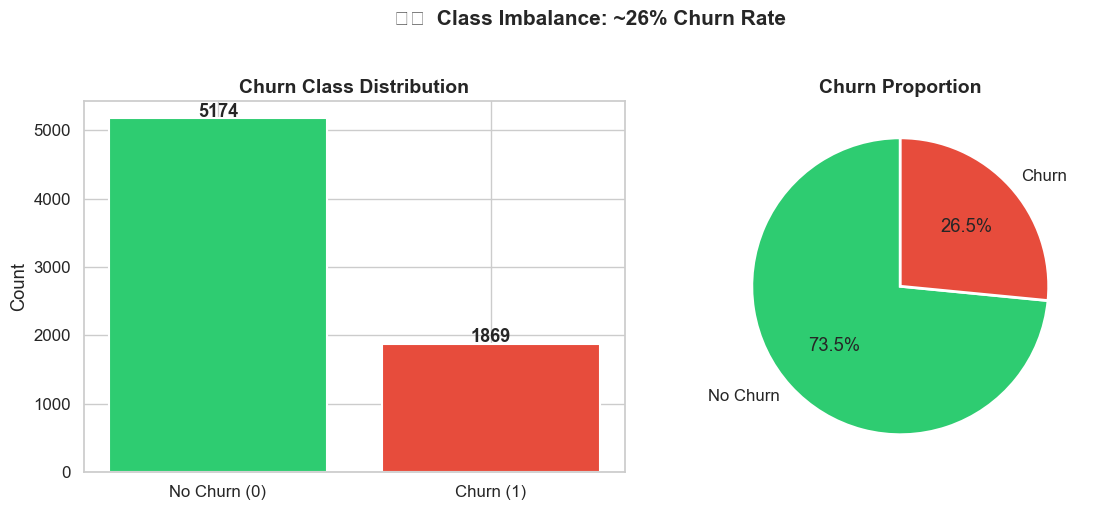


Churn rate: 26.54%
 Class imbalance must be handled (SMOTE / class_weight)


In [11]:

# ── Churn distribution ───────────────────────────────────────
churn_counts = df['Churn'].value_counts()
churn_pct    = df['Churn'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(['No Churn (0)', 'Churn (1)'], churn_counts.values,
            color=['#2ecc71', '#e74c3c'], edgecolor='white', linewidth=1.5)
for i, v in enumerate(churn_counts.values):
    axes[0].text(i, v + 30, str(v), ha='center', fontweight='bold', fontsize=13)
axes[0].set_title('Churn Class Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Count')

axes[1].pie(churn_counts.values, labels=['No Churn', 'Churn'],
            autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'],
            startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Churn Proportion', fontsize=14, fontweight='bold')

plt.suptitle('⚠️  Class Imbalance: ~26% Churn Rate', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"\nChurn rate: {churn_pct[1]:.2f}%")
print(" Class imbalance must be handled (SMOTE / class_weight)")


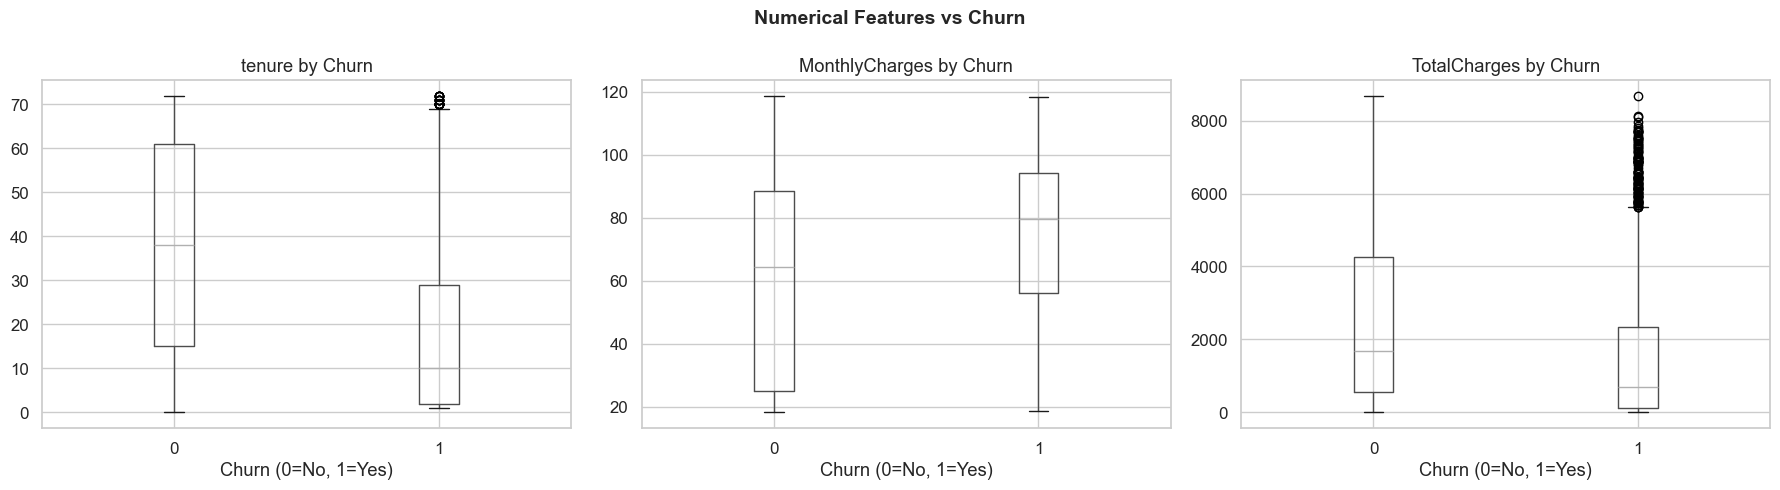

In [12]:

# ── Numerical features vs Churn ──────────────────────────────
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = df.select_dtypes(include='object').columns.drop(['customerID']).tolist()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(num_cols):
    df.boxplot(column=col, by='Churn', ax=axes[i])
    axes[i].set_title(f'{col} by Churn')
    axes[i].set_xlabel('Churn (0=No, 1=Yes)')
plt.suptitle('Numerical Features vs Churn', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


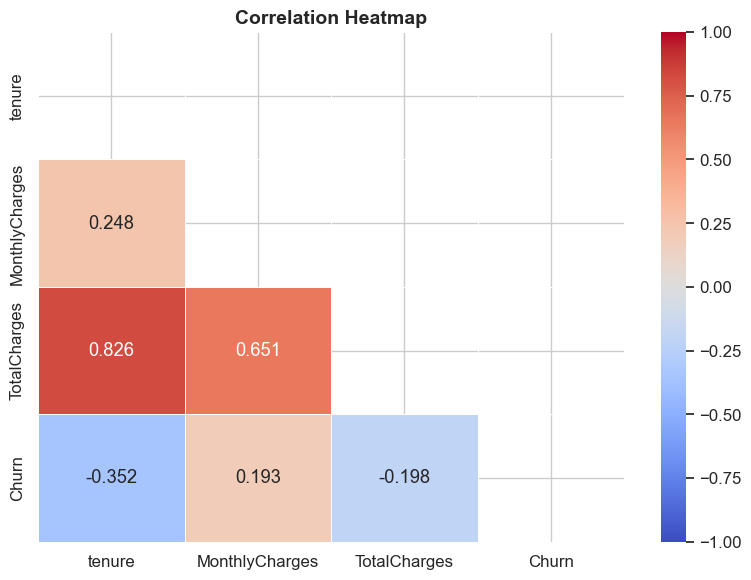


  TotalCharges & tenure are highly correlated (multicollinearity)


In [13]:

# ── Correlation heatmap (numerical + Churn) ───────────────────
corr = df[num_cols + ['Churn']].corr()
plt.figure(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.3f',
            mask=mask, linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print("\n  TotalCharges & tenure are highly correlated (multicollinearity)")


## 3. Feature Engineering & Encoding

### Key decisions:
- **One-Hot Encoding** for non-binary categoricals (avoids imposing ordinal relationships that LabelEncoder falsely implies for multiclass categories)
- **VIF analysis** to detect multicollinearity among numerical features
- **Chi² test** to rank categorical features by association with Churn
- **New engineered features** to capture domain logic


In [14]:

df_enc = df.copy()
df_enc.drop(columns=['customerID'], inplace=True)

# ── Feature Engineering ──────────────────────────────────────
# 1. Charge per tenure month (unit economics)
df_enc['AvgMonthlySpend'] = (
    df_enc['TotalCharges'] / (df_enc['tenure'] + 1)  # +1 to avoid /0
)

# 2. Has no additional services (risk proxy)
service_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']
df_enc['NoServices'] = (
    df_enc[service_cols]
    .apply(lambda x: (x == 'No internet service') | (x == 'No'), axis=0)
    .all(axis=1).astype(int)
)

# 3. Month-to-month contract flag (highest churn risk)
df_enc['IsMonthToMonth'] = (df_enc['Contract'] == 'Month-to-month').astype(int)

# 4. Tenure bucket
df_enc['TenureBucket'] = pd.cut(
    df_enc['tenure'],
    bins=[0, 12, 24, 48, 72],
    labels=['0-12m', '13-24m', '25-48m', '49-72m']
)

print("New features added:")
print(df_enc[['AvgMonthlySpend', 'NoServices', 'IsMonthToMonth', 'TenureBucket']].head())


New features added:
   AvgMonthlySpend  NoServices  IsMonthToMonth TenureBucket
0        14.925000           0               1        0-12m
1        53.985714           0               0       25-48m
2        36.050000           0               1        0-12m
3        40.016304           0               0       25-48m
4        50.550000           1               1        0-12m


In [15]:

# ── Binary columns ────────────────────────────────────────────
binary_yes_no = ['SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
                 'PaperlessBilling', 'NoServices', 'IsMonthToMonth']
for col in binary_yes_no:
    if df_enc[col].dtype == object:
        df_enc[col] = df_enc[col].map({'Yes': 1, 'No': 0, 'yes': 1, 'no': 0})

df_enc['gender'] = df_enc['gender'].map({'Male': 1, 'Female': 0})

# ── One-Hot Encoding for non-binary categoricals ───────────────
# (better than LabelEncoder — avoids false ordinal relationships)
ohe_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
            'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
            'Contract', 'PaymentMethod', 'TenureBucket']

df_enc = pd.get_dummies(df_enc, columns=ohe_cols, drop_first=True)

print(f"Shape after encoding: {df_enc.shape}")
df_enc.head(2)


Shape after encoding: (7043, 37)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureBucket_13-24m,TenureBucket_25-48m,TenureBucket_49-72m
0,0,0,1,0,1,0,1,29.85,29.85,0,...,False,False,False,False,False,True,False,False,False,False
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,False,False,True,False,False,False,True,False,True,False


In [16]:

# ── VIF Analysis (Variance Inflation Factor) ────────────────
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlySpend']
X_vif = sm.add_constant(df_enc[num_features])
vif_df = pd.DataFrame({
    'Feature': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
}).sort_values('VIF', ascending=False)
print("=== VIF Analysis ===")
print(vif_df.to_string(index=False))
print("\n VIF > 10 indicates severe multicollinearity")
print(" Removing TotalCharges (redundant: = tenure × MonthlyCharges)")

df_enc.drop(columns=['TotalCharges'], inplace=True)


=== VIF Analysis ===
        Feature       VIF
AvgMonthlySpend 20.025191
 MonthlyCharges 17.155575
          const 15.222891
   TotalCharges 10.006964
         tenure  5.957001

 VIF > 10 indicates severe multicollinearity
 Removing TotalCharges (redundant: = tenure × MonthlyCharges)


In [17]:

# ── Chi² test on original categorical features ───────────────
original_cat = ['SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
                'PaperlessBilling', 'gender']
# Filter to those still in df_enc
available = [c for c in original_cat if c in df_enc.columns]
X_chi2 = df_enc[available]
y_chi2 = df_enc['Churn']

chi_scores, p_values = chi2(X_chi2, y_chi2)
chi2_df = pd.DataFrame({
    'Feature': available,
    'Chi2 Score': chi_scores,
    'p-value': p_values,
    'Significant (p<0.05)': p_values < 0.05
}).sort_values('Chi2 Score', ascending=False)

print("=== Chi² Feature Importance ===")
print(chi2_df.to_string(index=False))

# Remove statistically insignificant features with low chi2
drop_features = chi2_df[
    (chi2_df['p-value'] > 0.05) & (chi2_df['Chi2 Score'] < 1)
]['Feature'].tolist()
if drop_features:
    df_enc.drop(columns=drop_features, inplace=True)
    print(f"\n Dropped: {drop_features}")
else:
    print("\n All features pass Chi² test")


=== Chi² Feature Importance ===
         Feature  Chi2 Score      p-value  Significant (p<0.05)
   SeniorCitizen  134.351545 4.576959e-31                  True
      Dependents  133.036443 8.876729e-31                  True
PaperlessBilling  105.680863 8.661987e-25                  True
         Partner   82.412083 1.104764e-19                  True
          gender    0.258699 6.110156e-01                 False
    PhoneService    0.097261 7.551421e-01                 False

 Dropped: ['gender', 'PhoneService']


## 4. Train / Test Split (Stratified)

In [18]:

X = df_enc.drop(columns=['Churn'])
y = df_enc['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Train size: {X_train.shape[0]} samples | "
      f"Churn rate: {y_train.mean()*100:.2f}%")
print(f"Test  size: {X_test.shape[0]}  samples | "
      f"Churn rate: {y_test.mean()*100:.2f}%")

# ── Preprocessor (StandardScaler on numeric only) ────────────
num_cols_model = ['tenure', 'MonthlyCharges', 'AvgMonthlySpend']
num_cols_model = [c for c in num_cols_model if c in X.columns]

preprocessor = ColumnTransformer(
    transformers=[('num', StandardScaler(), num_cols_model)],
    remainder='passthrough'
)

# Scale for CV analysis
from sklearn.preprocessing import StandardScaler as SS
scale_pos_weight_value = (y_train == 0).sum() / (y_train == 1).sum()
print(f"\nscale_pos_weight = {scale_pos_weight_value:.3f}  "
      f"(used in XGBoost / LightGBM for class imbalance)")


Train size: 5634 samples | Churn rate: 26.54%
Test  size: 1409  samples | Churn rate: 26.54%

scale_pos_weight = 2.769  (used in XGBoost / LightGBM for class imbalance)


## 5. Class Imbalance Handling

### Techniques compared:
| Technique | Mechanism | Risk |
|---|---|---|
| `class_weight='balanced'` | Penalises misclassification of minority class | None — no data duplication |
| `SMOTE` | Synthetically creates minority samples via KNN interpolation | Risk of overfitting if applied before CV split |
| `BorderlineSMOTE` | SMOTE only on borderline samples (harder cases) | Same as SMOTE, but more targeted |

> **Critical rule**: SMOTE must be applied **inside** the cross-validation loop to avoid data leakage. We use `imblearn.pipeline` for this.


No resampling (class_weight)             | Recall: 0.7906 ± 0.0343
SMOTE                                    | Recall: 0.7766 ± 0.0348
BorderlineSMOTE                          | Recall: 0.8274 ± 0.0309


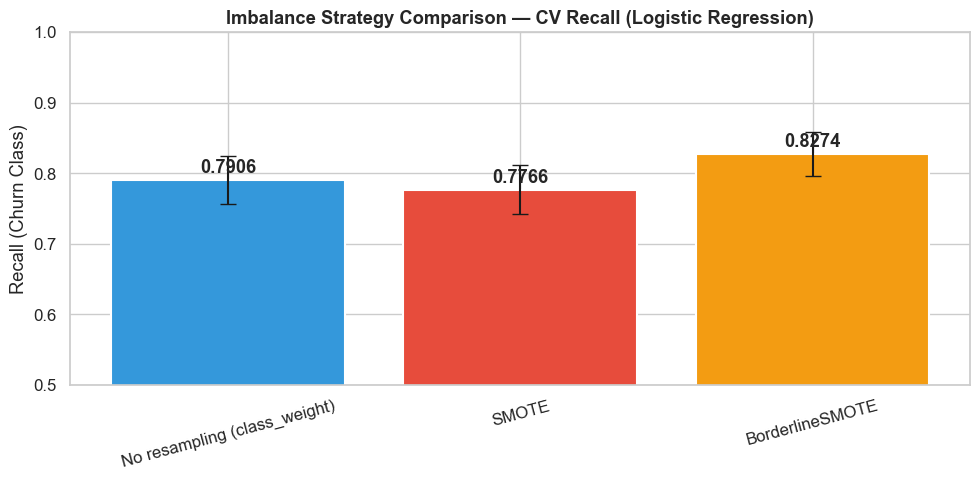


 Best strategy will be used inside final model pipelines


In [19]:

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, BorderlineSMOTE

# ── Quick recall comparison across strategies ────────────────
recall_scorer = make_scorer(recall_score)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

strategies = {
    'No resampling (class_weight)': Pipeline([
        ('pre', preprocessor),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE))
    ]),
    'SMOTE': ImbPipeline([
        ('pre', preprocessor),
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    'BorderlineSMOTE': ImbPipeline([
        ('pre', preprocessor),
        ('bsmote', BorderlineSMOTE(random_state=RANDOM_STATE)),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
}

imbalance_results = {}
for name, pipe in strategies.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv5,
                             scoring='recall', n_jobs=-1)
    imbalance_results[name] = scores
    print(f"{name:40s} | Recall: {scores.mean():.4f} ± {scores.std():.4f}")

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
labels = list(imbalance_results.keys())
means  = [v.mean() for v in imbalance_results.values()]
stds   = [v.std()  for v in imbalance_results.values()]
bars = ax.bar(labels, means, yerr=stds, capsize=6,
              color=['#3498db', '#e74c3c', '#f39c12'], edgecolor='white', linewidth=1.5)
for bar, m in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{m:.4f}', ha='center', fontweight='bold')
ax.set_ylabel('Recall (Churn Class)')
ax.set_title('Imbalance Strategy Comparison — CV Recall (Logistic Regression)', fontweight='bold')
ax.set_ylim(0.5, 1.0)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print("\n Best strategy will be used inside final model pipelines")


## 6. Professional Evaluation Framework

In [20]:

def evaluate_model(model, X_train, y_train, X_test, y_test, model_name,
                   threshold=0.5, cost_fn=500, cost_fp=50):
    """
    Full evaluation: metrics, overfitting analysis, confusion matrix, ROC curve.
    
    Parameters
    ----------
    cost_fn : cost of false negative (missed churner) in USD
    cost_fp : cost of false positive (unnecessary retention offer) in USD
    """
    y_train_proba = model.predict_proba(X_train)[:, 1]
    y_test_proba  = model.predict_proba(X_test)[:, 1]
    
    y_train_pred = (y_train_proba >= threshold).astype(int)
    y_test_pred  = (y_test_proba  >= threshold).astype(int)

    # ── Core metrics ─────────────────────────────────────────
    metrics = {
        'Model': model_name,
        'Threshold': threshold,
        'Train Accuracy':        model.score(X_train, y_train),
        'Test Accuracy':         (y_test_pred == y_test).mean(),
        'Train F1 (churn)':      f1_score(y_train, y_train_pred),
        'Test F1 (churn)':       f1_score(y_test, y_test_pred),
        'Train Recall (churn)':  recall_score(y_train, y_train_pred),
        'Test Recall (churn)':   recall_score(y_test, y_test_pred),
        'Test Precision (churn)':precision_score(y_test, y_test_pred, zero_division=0),
        'Train AUC-ROC':         roc_auc_score(y_train, y_train_proba),
        'Test AUC-ROC':          roc_auc_score(y_test, y_test_proba),
        'Test PR-AUC':           average_precision_score(y_test, y_test_proba),
        'Brier Score':           brier_score_loss(y_test, y_test_proba),
    }
    
    # ── Overfitting analysis ──────────────────────────────────
    recall_gap   = metrics['Train Recall (churn)'] - metrics['Test Recall (churn)']
    auc_gap      = metrics['Train AUC-ROC']        - metrics['Test AUC-ROC']
    overfitting_flag = "  OVERFIT" if (auc_gap > 0.05 or recall_gap > 0.1) else "✓ OK"
    
    # ── Business cost ────────────────────────────────────────
    cm = confusion_matrix(y_test, y_test_pred)
    tn, fp, fn, tp = cm.ravel()
    business_cost = fn * cost_fn + fp * cost_fp
    metrics['Business Cost ($)'] = business_cost
    metrics['FN (missed churners)'] = fn
    metrics['FP (false alarms)'] = fp

    # ── Print summary ─────────────────────────────────────────
    print(f"\n{'='*60}")
    print(f"  {model_name}  [{overfitting_flag}]")
    print(f"{'='*60}")
    print(classification_report(y_test, y_test_pred,
          target_names=['No Churn', 'Churn']))
    
    print(f"  {'Metric':<25} {'Train':>10} {'Test':>10} {'Gap':>10}")
    print(f"  {'-'*55}")
    for m in ['Accuracy', 'F1 (churn)', 'Recall (churn)', 'AUC-ROC']:
        tr = metrics.get(f'Train {m}', 0)
        te = metrics.get(f'Test {m}', 0)
        gap = tr - te
        flag = '  overfit' if abs(gap) > 0.05 else ''
        print(f"  {m:<25} {tr:>10.4f} {te:>10.4f} {gap:>+10.4f}{flag}")
    
    print(f"\n  PR-AUC: {metrics['Test PR-AUC']:.4f}  |  "
          f"Brier Score: {metrics['Brier Score']:.4f}  |  "
          f"Business Cost: ${business_cost:,.0f}")

    # ── Plots ────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Confusion matrix
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['No Churn', 'Churn'],
                yticklabels=['No Churn', 'Churn'])
    axes[0].set_title(f'Confusion Matrix\n(threshold={threshold})', fontweight='bold')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('Actual')
    
    # ROC curve
    fpr_tr, tpr_tr, _ = roc_curve(y_train, y_train_proba)
    fpr_te, tpr_te, _ = roc_curve(y_test, y_test_proba)
    axes[1].plot(fpr_tr, tpr_tr, label=f'Train AUC={metrics["Train AUC-ROC"]:.3f}', linestyle='--')
    axes[1].plot(fpr_te, tpr_te, label=f'Test  AUC={metrics["Test AUC-ROC"]:.3f}',  linewidth=2)
    axes[1].plot([0,1],[0,1],'k--', alpha=0.3, label='Random')
    axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
    axes[1].set_title('ROC Curve (Train vs Test)', fontweight='bold')
    axes[1].legend()
    
    # PR curve
    prec, rec, _ = precision_recall_curve(y_test, y_test_proba)
    axes[2].plot(rec, prec, linewidth=2, color='darkorange')
    axes[2].axhline(y_test.mean(), linestyle='--', color='gray',
                    label=f'Baseline={y_test.mean():.3f}')
    axes[2].set_xlabel('Recall'); axes[2].set_ylabel('Precision')
    axes[2].set_title(f'Precision-Recall Curve\nPR-AUC={metrics["Test PR-AUC"]:.3f}',
                      fontweight='bold')
    axes[2].legend()
    
    plt.suptitle(model_name, fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
    
    return metrics


## 7. Baseline Models

Each model is trained with **anti-overfitting settings from the start**:
- Random Forest: `max_depth=10`, `min_samples_leaf=5` (vs original: unlimited depth → 99.7% train accuracy)
- KNN: `n_neighbors=15` (vs original: `n_neighbors=5` → severe overfitting)
- XGBoost: `max_depth=5`, `reg_alpha`, `reg_lambda` (regularisation)



  Logistic Regression (Baseline)  [✓ OK]
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.80      1035
       Churn       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

  Metric                         Train       Test        Gap
  -------------------------------------------------------
  Accuracy                      0.7549     0.7395    +0.0153
  F1 (churn)                    0.6330     0.6133    +0.0197
  Recall (churn)                0.7967     0.7781    +0.0186
  AUC-ROC                       0.8517     0.8444    +0.0073

  PR-AUC: 0.6557  |  Brier Score: 0.1654  |  Business Cost: $55,700


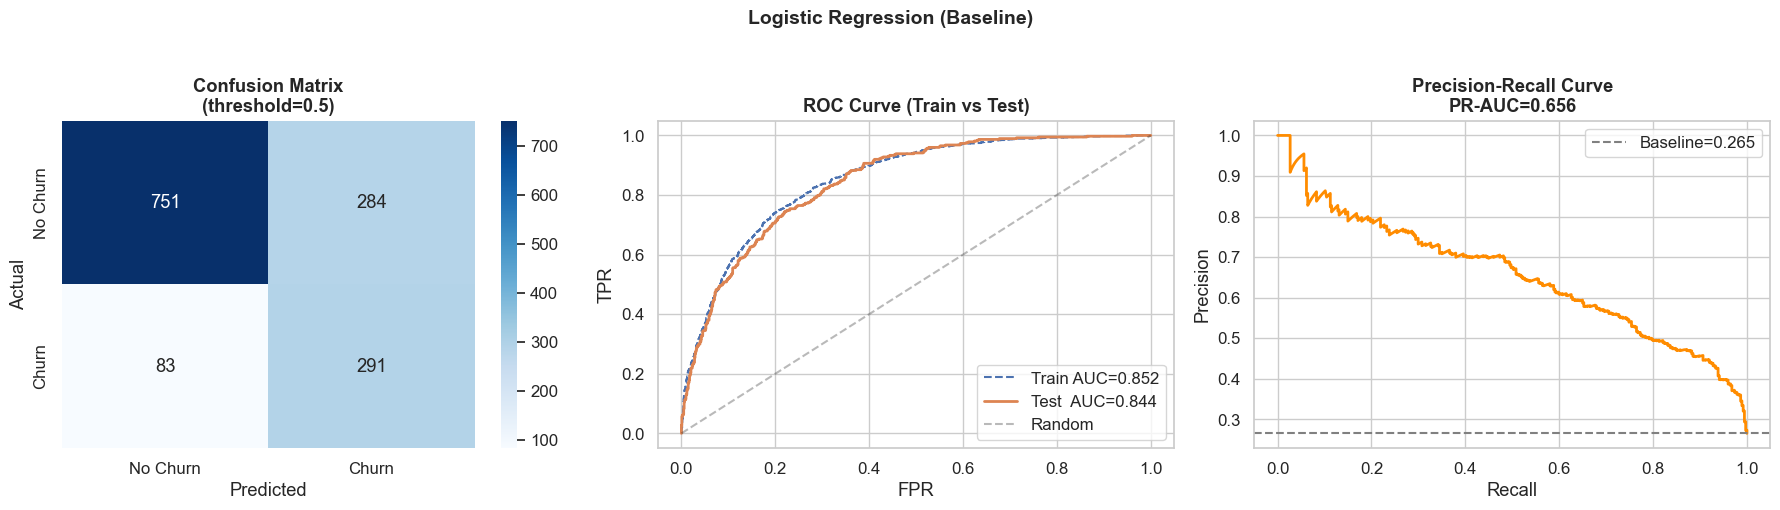

In [21]:

all_results = []

# ── 1. Logistic Regression ───────────────────────────────────
lr_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', LogisticRegression(
        class_weight='balanced', C=1.0,
        max_iter=2000, random_state=RANDOM_STATE
    ))
])
lr_pipe.fit(X_train, y_train)
all_results.append(evaluate_model(lr_pipe, X_train, y_train, X_test, y_test,
                                   "Logistic Regression (Baseline)"))



  Random Forest (Baseline)  [  OVERFIT]
              precision    recall  f1-score   support

    No Churn       0.90      0.76      0.83      1035
       Churn       0.54      0.78      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.78      1409

  Metric                         Train       Test        Gap
  -------------------------------------------------------
  Accuracy                      0.8049     0.7644    +0.0406
  F1 (churn)                    0.6995     0.6360    +0.0635  overfit
  Recall (churn)                0.8555     0.7754    +0.0801  overfit
  AUC-ROC                       0.9074     0.8433    +0.0641  overfit

  PR-AUC: 0.6543  |  Brier Score: 0.1565  |  Business Cost: $54,400


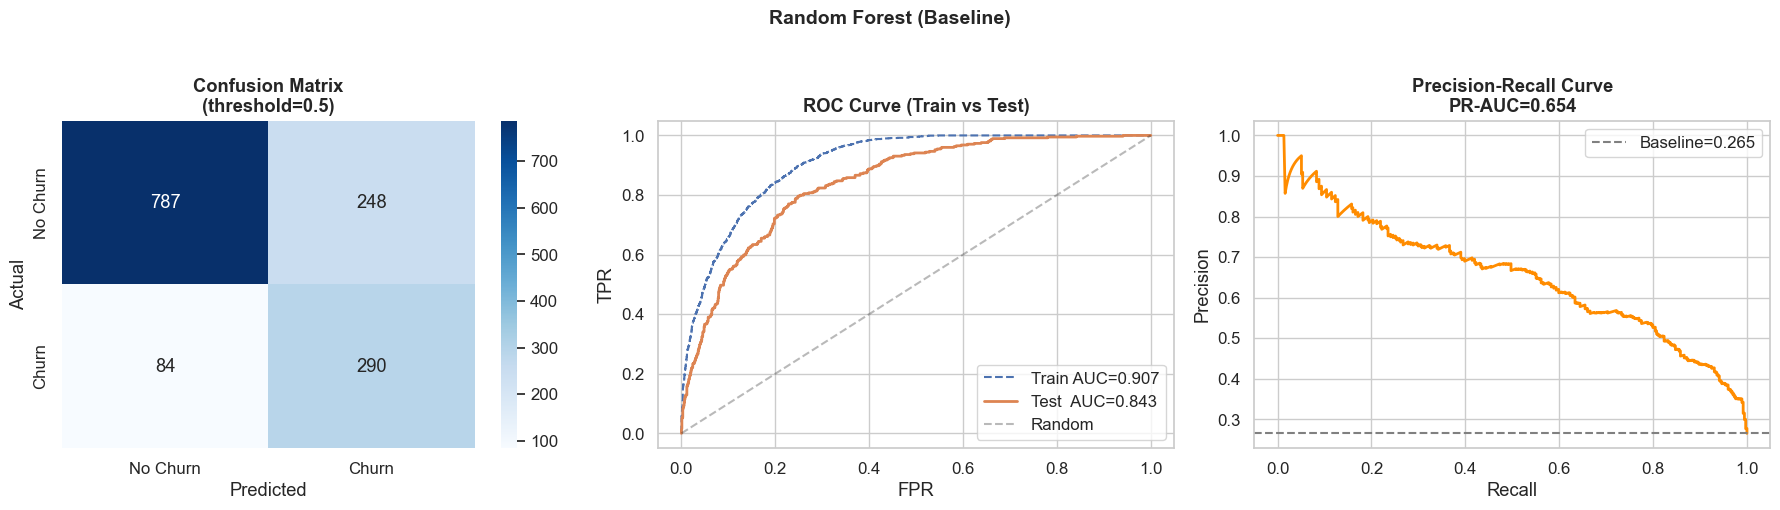

In [22]:

# ── 2. Random Forest — ANTI-OVERFITTING ────────────────────
# Original had no max_depth → 99.7% train accuracy (severe overfit)
# Fix: max_depth=10, min_samples_leaf=5, min_samples_split=10
rf_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', RandomForestClassifier(
        n_estimators=200,
        max_depth=10,           # ← was None (overfit)
        min_samples_leaf=5,     # ← was 1 (overfit)
        min_samples_split=10,   # ← was 2 (overfit)
        class_weight='balanced',
        max_features='sqrt',
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])
rf_pipe.fit(X_train, y_train)
all_results.append(evaluate_model(rf_pipe, X_train, y_train, X_test, y_test,
                                   "Random Forest (Baseline)"))



  KNN (Baseline)  [  OVERFIT]
              precision    recall  f1-score   support

    No Churn       0.83      0.86      0.85      1035
       Churn       0.57      0.53      0.55       374

    accuracy                           0.77      1409
   macro avg       0.70      0.69      0.70      1409
weighted avg       0.76      0.77      0.77      1409

  Metric                         Train       Test        Gap
  -------------------------------------------------------
  Accuracy                      0.9977     0.7693    +0.2284  overfit
  F1 (churn)                    0.9957     0.5480    +0.4477  overfit
  Recall (churn)                0.9960     0.5267    +0.4692  overfit
  AUC-ROC                       1.0000     0.8040    +0.1960  overfit

  PR-AUC: 0.5898  |  Brier Score: 0.1548  |  Business Cost: $95,900


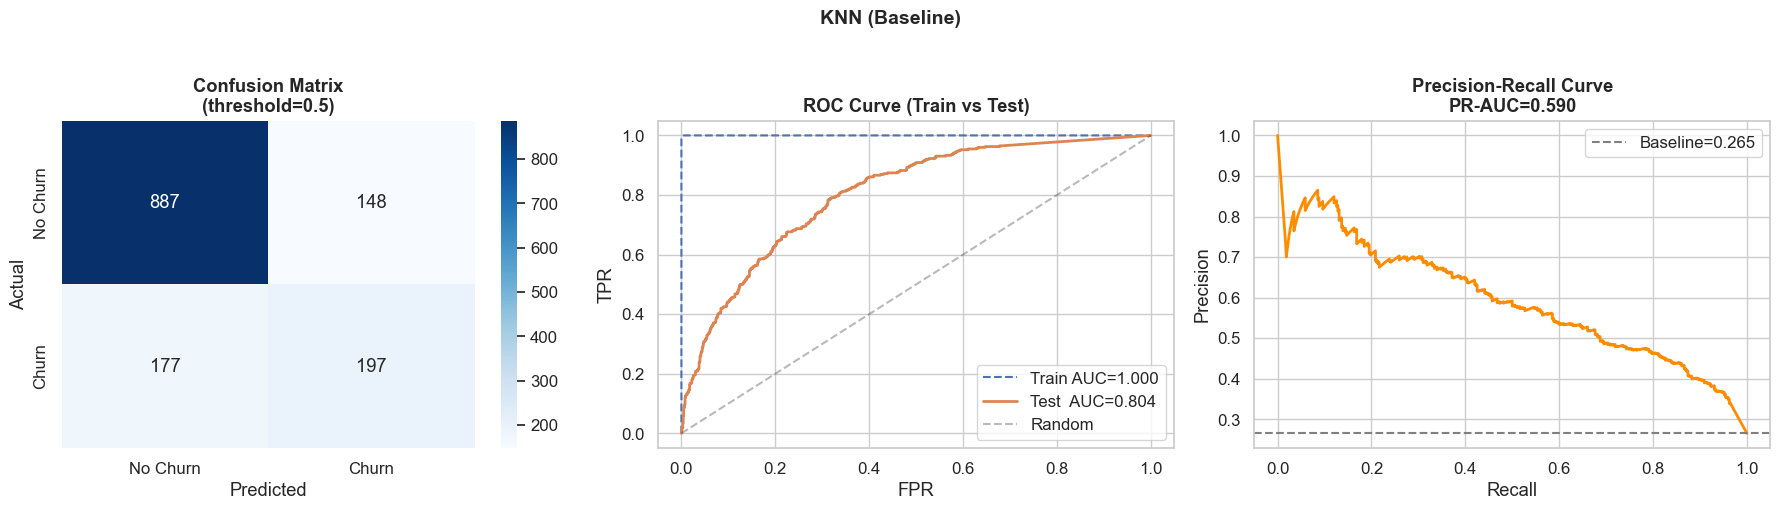

In [23]:

# ── 3. KNN — ANTI-OVERFITTING ──────────────────────────────
# Original n_neighbors=5 → 99.7% train accuracy on scaled data
# Fix: n_neighbors=15 (smoother decision boundary)
knn_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', KNeighborsClassifier(n_neighbors=15, weights='distance', p=2))
])
knn_pipe.fit(X_train, y_train)
all_results.append(evaluate_model(knn_pipe, X_train, y_train, X_test, y_test,
                                   "KNN (Baseline)"))



  XGBoost (Baseline)  [  OVERFIT]
              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409

  Metric                         Train       Test        Gap
  -------------------------------------------------------
  Accuracy                      0.8271     0.7601    +0.0670  overfit
  F1 (churn)                    0.7324     0.6318    +0.1006  overfit
  Recall (churn)                0.8916     0.7754    +0.1162  overfit
  AUC-ROC                       0.9231     0.8375    +0.0855  overfit

  PR-AUC: 0.6437  |  Brier Score: 0.1619  |  Business Cost: $54,700


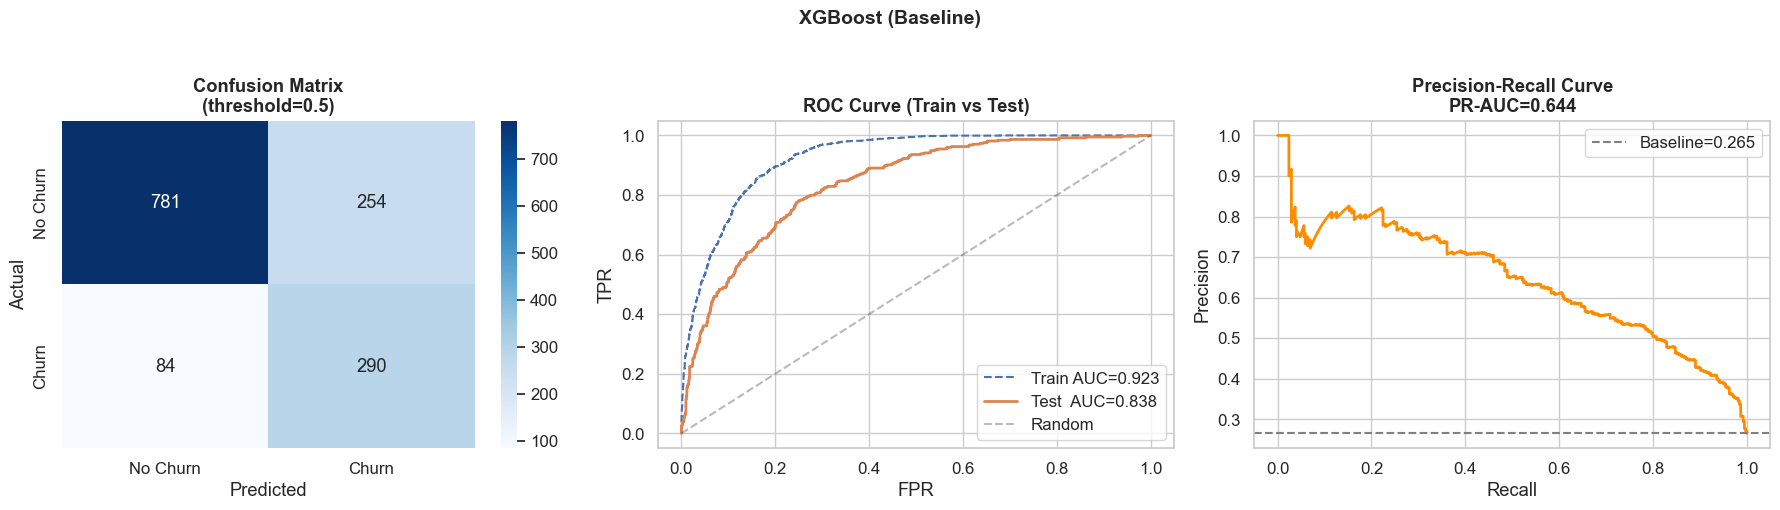

In [24]:

# ── 4. XGBoost — ANTI-OVERFITTING ─────────────────────────
# Original: max_depth up to 15 searched, no early stopping
# Fix: constrained depth, L1/L2 regularisation, scale_pos_weight
xgb_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', XGBClassifier(
        n_estimators=300,
        max_depth=5,                          # ← constrained
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        gamma=1.0,                            # ← pruning
        reg_alpha=0.5,                        # ← L1
        reg_lambda=1.5,                       # ← L2
        min_child_weight=5,
        scale_pos_weight=scale_pos_weight_value,
        eval_metric='auc',
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=0
    ))
])
xgb_pipe.fit(X_train, y_train)
all_results.append(evaluate_model(xgb_pipe, X_train, y_train, X_test, y_test,
                                   "XGBoost (Baseline)"))



  LightGBM (Baseline)  [  OVERFIT]
              precision    recall  f1-score   support

    No Churn       0.89      0.76      0.82      1035
       Churn       0.53      0.74      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.76      0.77      1409

  Metric                         Train       Test        Gap
  -------------------------------------------------------
  Accuracy                      0.8655     0.7573    +0.1082  overfit
  F1 (churn)                    0.7896     0.6183    +0.1713  overfit
  Recall (churn)                0.9512     0.7406    +0.2105  overfit
  AUC-ROC                       0.9527     0.8332    +0.1195  overfit

  PR-AUC: 0.6359  |  Brier Score: 0.1611  |  Business Cost: $60,750


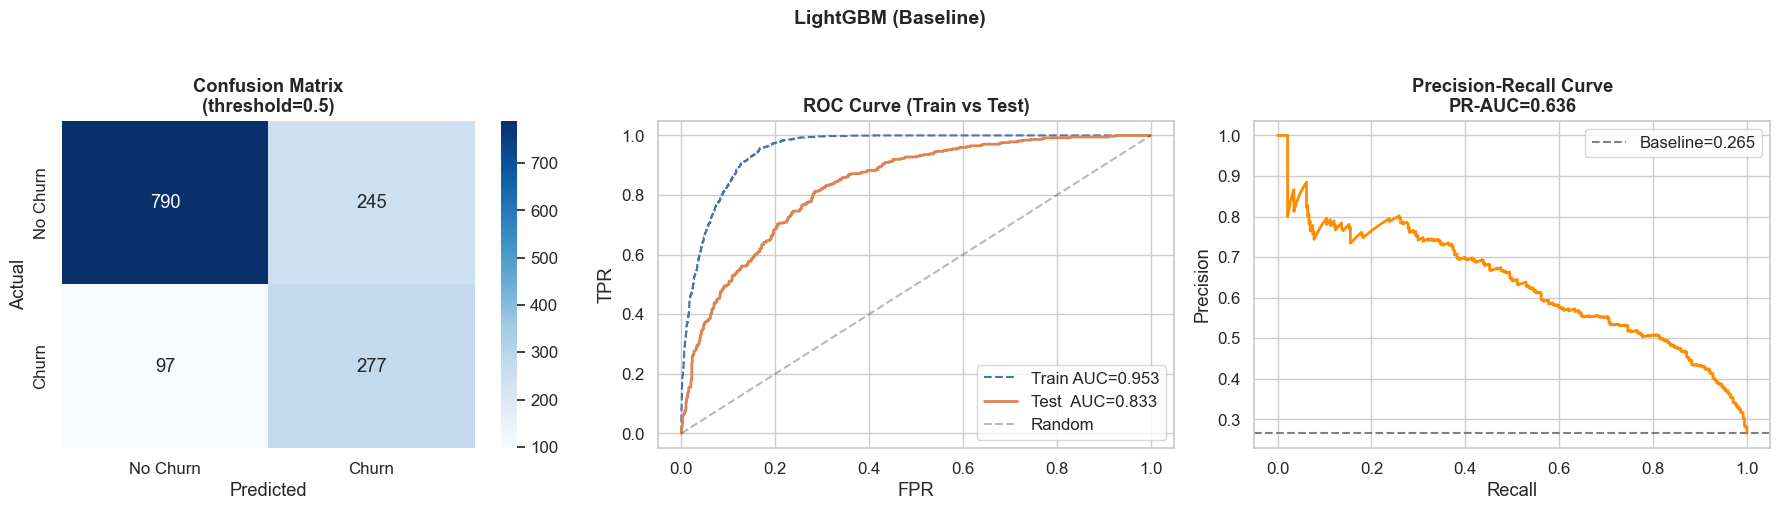

In [25]:

# ── 5. LightGBM ──────────────────────────────────────────
lgbm_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', LGBMClassifier(
        n_estimators=300,
        max_depth=7,
        num_leaves=31,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_samples=20,
        reg_alpha=0.3,
        reg_lambda=0.3,
        scale_pos_weight=scale_pos_weight_value,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    ))
])
lgbm_pipe.fit(X_train, y_train)
all_results.append(evaluate_model(lgbm_pipe, X_train, y_train, X_test, y_test,
                                   "LightGBM (Baseline)"))



  CatBoost (Baseline)  [  OVERFIT]
              precision    recall  f1-score   support

    No Churn       0.90      0.76      0.82      1035
       Churn       0.54      0.77      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409

  Metric                         Train       Test        Gap
  -------------------------------------------------------
  Accuracy                      0.8191     0.7622    +0.0569  overfit
  F1 (churn)                    0.7236     0.6323    +0.0914  overfit
  Recall (churn)                0.8923     0.7701    +0.1223  overfit
  AUC-ROC                       0.9136     0.8412    +0.0724  overfit

  PR-AUC: 0.6624  |  Brier Score: 0.1606  |  Business Cost: $55,450


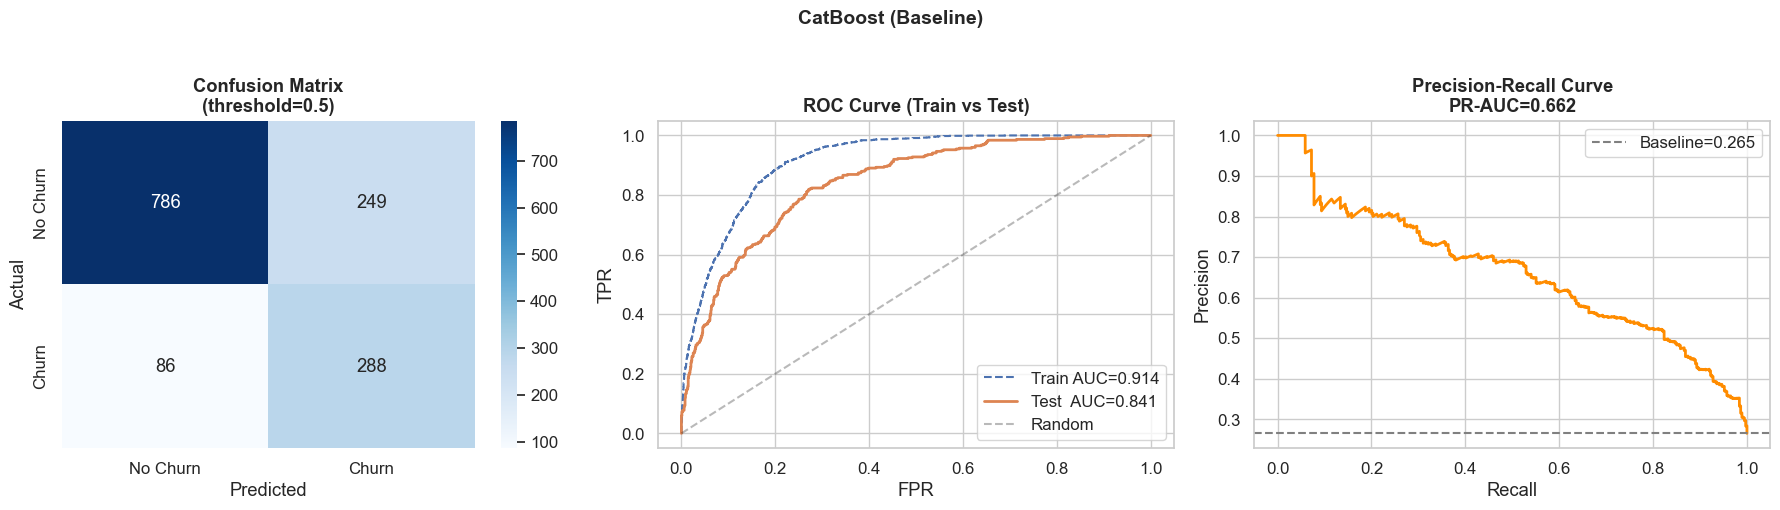

In [26]:

# ── 6. CatBoost ──────────────────────────────────────────
catboost_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', CatBoostClassifier(
        iterations=300,
        depth=6,
        learning_rate=0.05,
        l2_leaf_reg=5,
        border_count=64,
        class_weights=[1, scale_pos_weight_value],
        eval_metric='AUC',
        random_seed=RANDOM_STATE,
        verbose=0
    ))
])
catboost_pipe.fit(X_train, y_train)
all_results.append(evaluate_model(catboost_pipe, X_train, y_train, X_test, y_test,
                                   "CatBoost (Baseline)"))


## 8. Advanced Cross-Validation

### Stratified K-Fold (5 folds)
- Preserves class proportions in each fold
- Gives reliable, unbiased estimate of generalisation

### Nested Cross-Validation
- Outer loop: model evaluation
- Inner loop: hyperparameter selection
- Prevents **selection bias** (optimistic results from evaluating tuned models on the same fold used for tuning)


In [27]:

cv_models = {
    'Logistic Regression': Pipeline([
        ('pre', preprocessor),
        ('clf', LogisticRegression(class_weight='balanced', C=1.0,
                                   max_iter=2000, random_state=RANDOM_STATE))
    ]),
    'Random Forest': Pipeline([
        ('pre', preprocessor),
        ('clf', RandomForestClassifier(n_estimators=200, max_depth=10,
                                        min_samples_leaf=5, class_weight='balanced',
                                        random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    'XGBoost': Pipeline([
        ('pre', preprocessor),
        ('clf', XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05,
                               gamma=1.0, reg_alpha=0.5, reg_lambda=1.5,
                               scale_pos_weight=scale_pos_weight_value,
                               eval_metric='auc', random_state=RANDOM_STATE,
                               n_jobs=-1, verbosity=0))
    ]),
    'LightGBM': Pipeline([
        ('pre', preprocessor),
        ('clf', LGBMClassifier(n_estimators=200, max_depth=7, num_leaves=31,
                                learning_rate=0.05, scale_pos_weight=scale_pos_weight_value,
                                random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1))
    ]),
    'CatBoost': Pipeline([
        ('pre', preprocessor),
        ('clf', CatBoostClassifier(iterations=200, depth=6, learning_rate=0.05,
                                    class_weights=[1, scale_pos_weight_value],
                                    eval_metric='AUC', random_seed=RANDOM_STATE, verbose=0))
    ]),
}

scoring_metrics = {
    'recall':  make_scorer(recall_score),
    'f1':      make_scorer(f1_score),
    'roc_auc': 'roc_auc',
    'pr_auc':  make_scorer(average_precision_score, needs_proba=True),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_summary = {}
print(f"{'Model':<22} {'Recall':>12} {'F1':>12} {'AUC-ROC':>12} {'PR-AUC':>12} {'Stability':>12}")
print('-' * 84)

for name, pipe in cv_models.items():
    cv_res = cross_validate(pipe, X_train, y_train, cv=skf,
                             scoring=scoring_metrics, n_jobs=-1)
    row = {}
    stabilities = []
    for met in ['recall', 'f1', 'roc_auc', 'pr_auc']:
        scores = cv_res[f'test_{met}']
        row[met] = scores
        stabilities.append(scores.std())
    stability = np.mean(stabilities)
    cv_summary[name] = row
    print(f"{name:<22} "
          f"{row['recall'].mean():>6.4f}±{row['recall'].std():.3f}  "
          f"{row['f1'].mean():>6.4f}±{row['f1'].std():.3f}  "
          f"{row['roc_auc'].mean():>6.4f}±{row['roc_auc'].std():.3f}  "
          f"{row['pr_auc'].mean():>6.4f}±{row['pr_auc'].std():.3f}  "
          f"{stability:>10.4f}")

print("\nStability = mean std across metrics (lower = more stable)")


Model                        Recall           F1      AUC-ROC       PR-AUC    Stability
------------------------------------------------------------------------------------
Logistic Regression    0.7906±0.034  0.6296±0.020  0.8480±0.011     nan±nan         nan
Random Forest          0.7592±0.026  0.6334±0.014  0.8467±0.011     nan±nan         nan
XGBoost                0.7806±0.016  0.6293±0.014  0.8446±0.012     nan±nan         nan
LightGBM               0.7425±0.024  0.6249±0.015  0.8366±0.012     nan±nan         nan
CatBoost               0.7773±0.026  0.6296±0.017  0.8469±0.010     nan±nan         nan

Stability = mean std across metrics (lower = more stable)


In [28]:

# ── Nested CV for best model (LightGBM) ─────────────────────
print("=== Nested Cross-Validation: LightGBM ===")

inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv  = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_dist_nested = {
    'clf__n_estimators': [100, 200, 300],
    'clf__max_depth': [5, 7, 9],
    'clf__num_leaves': [20, 31, 50],
}

nested_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', LGBMClassifier(learning_rate=0.05, scale_pos_weight=scale_pos_weight_value,
                            random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1))
])

inner_search = GridSearchCV(nested_pipe, param_dist_nested,
                             scoring='recall', cv=inner_cv, n_jobs=-1)

nested_scores = cross_val_score(inner_search, X_train, y_train,
                                 cv=outer_cv, scoring='recall', n_jobs=-1)

print(f"Nested CV Recall: {nested_scores.mean():.4f} ± {nested_scores.std():.4f}")
print(f"Individual fold scores: {nested_scores.round(4)}")
print(f"\nInterpretation:")
print(f"   Mean {nested_scores.mean():.4f} = unbiased expected recall on unseen data")
print(f"   Std  {nested_scores.std():.4f}  = model stability across different data splits")


=== Nested Cross-Validation: LightGBM ===
Nested CV Recall: 0.7839 ± 0.0192
Individual fold scores: [0.786  0.7559 0.7826 0.8161 0.7793]

Interpretation:
   Mean 0.7839 = unbiased expected recall on unseen data
   Std  0.0192  = model stability across different data splits


## 9. Hyperparameter Tuning (Recall-Optimised)

**Critical change from original**: We now optimise for **Recall** (not AUC-ROC).  
Reason: in churn prediction, missing a churner (false negative) costs far more than a false alarm (false positive).


In [29]:

recall_scorer = make_scorer(recall_score)
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ── LightGBM tuning ──────────────────────────────────────────
lgbm_tune_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', LGBMClassifier(scale_pos_weight=scale_pos_weight_value,
                            random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1))
])

param_dist_lgbm = {
    'clf__n_estimators':      randint(150, 500),
    'clf__max_depth':         randint(3, 8),      # ← narrowed to prevent overfit
    'clf__num_leaves':        randint(15, 60),
    'clf__learning_rate':     uniform(0.02, 0.15),
    'clf__subsample':         uniform(0.7, 0.25),
    'clf__colsample_bytree':  uniform(0.7, 0.25),
    'clf__min_child_samples': randint(15, 60),
    'clf__reg_alpha':         uniform(0.0, 1.0),
    'clf__reg_lambda':        uniform(0.0, 1.5),
}

rs_lgbm = RandomizedSearchCV(
    lgbm_tune_pipe, param_dist_lgbm,
    n_iter=60, scoring=recall_scorer,  # ← recall, not AUC!
    cv=skf5, random_state=RANDOM_STATE, n_jobs=-1, verbose=0
)
rs_lgbm.fit(X_train, y_train)

print("Best LightGBM params (recall-optimised):")
for k, v in rs_lgbm.best_params_.items():
    print(f"  {k}: {v}")
print(f"  CV Recall: {rs_lgbm.best_score_:.4f}")


Best LightGBM params (recall-optimised):
  clf__colsample_bytree: 0.8237942275278175
  clf__learning_rate: 0.02515827816728276
  clf__max_depth: 3
  clf__min_child_samples: 50
  clf__n_estimators: 199
  clf__num_leaves: 54
  clf__reg_alpha: 0.7553614103176525
  clf__reg_lambda: 0.637733811736867
  clf__subsample: 0.7519854157170471
  CV Recall: 0.8140


In [30]:

# ── XGBoost tuning ────────────────────────────────────────
xgb_tune_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', XGBClassifier(scale_pos_weight=scale_pos_weight_value,
                           eval_metric='auc', random_state=RANDOM_STATE,
                           n_jobs=-1, verbosity=0))
])

param_dist_xgb = {
    'clf__n_estimators':     randint(150, 500),
    'clf__max_depth':        randint(3, 7),     # ← constrained (was 3-15)
    'clf__learning_rate':    uniform(0.02, 0.15),
    'clf__subsample':        uniform(0.7, 0.25),
    'clf__colsample_bytree': uniform(0.7, 0.25),
    'clf__gamma':            uniform(0.5, 2.0),  # ← pruning
    'clf__reg_alpha':        uniform(0.0, 2.0),
    'clf__reg_lambda':       uniform(0.5, 2.0),
    'clf__min_child_weight': randint(3, 15),
}

rs_xgb = RandomizedSearchCV(
    xgb_tune_pipe, param_dist_xgb,
    n_iter=60, scoring=recall_scorer,
    cv=skf5, random_state=RANDOM_STATE, n_jobs=-1, verbose=0
)
rs_xgb.fit(X_train, y_train)

print("Best XGBoost params (recall-optimised):")
for k, v in rs_xgb.best_params_.items():
    print(f"  {k}: {v}")
print(f"  CV Recall: {rs_xgb.best_score_:.4f}")


Best XGBoost params (recall-optimised):
  clf__colsample_bytree: 0.8700768846469449
  clf__gamma: 1.400998503939086
  clf__learning_rate: 0.02198974417397998
  clf__max_depth: 3
  clf__min_child_weight: 14
  clf__n_estimators: 163
  clf__reg_alpha: 1.6167946962329223
  clf__reg_lambda: 1.1092275383467414
  clf__subsample: 0.724418028501596
  CV Recall: 0.8167


In [31]:

# ── Logistic Regression tuning ──────────────────────────────
lr_tune_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
])

param_dist_lr = {
    'clf__C':             uniform(0.001, 10),
    'clf__penalty':       ['l1', 'l2'],
    'clf__solver':        ['liblinear', 'saga'],
    'clf__class_weight':  [None, 'balanced'],
}

rs_lr = RandomizedSearchCV(
    lr_tune_pipe, param_dist_lr,
    n_iter=40, scoring=recall_scorer,
    cv=skf5, random_state=RANDOM_STATE, n_jobs=-1, verbose=0
)
rs_lr.fit(X_train, y_train)

print("Best LR params (recall-optimised):")
for k, v in rs_lr.best_params_.items():
    print(f"  {k}: {v}")
print(f"  CV Recall: {rs_lr.best_score_:.4f}")


Best LR params (recall-optimised):
  clf__C: 1.196942459383017
  clf__class_weight: balanced
  clf__penalty: l1
  clf__solver: liblinear
  CV Recall: 0.7920



  LightGBM (Optimised)  [✓ OK]
              precision    recall  f1-score   support

    No Churn       0.91      0.73      0.81      1035
       Churn       0.52      0.81      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409

  Metric                         Train       Test        Gap
  -------------------------------------------------------
  Accuracy                      0.8395     0.7480    +0.0914  overfit
  F1 (churn)                    0.6459     0.6298    +0.0161
  Recall (churn)                0.8395     0.8075    +0.0320
  AUC-ROC                       0.8635     0.8467    +0.0168

  PR-AUC: 0.6567  |  Brier Score: 0.1633  |  Business Cost: $50,150


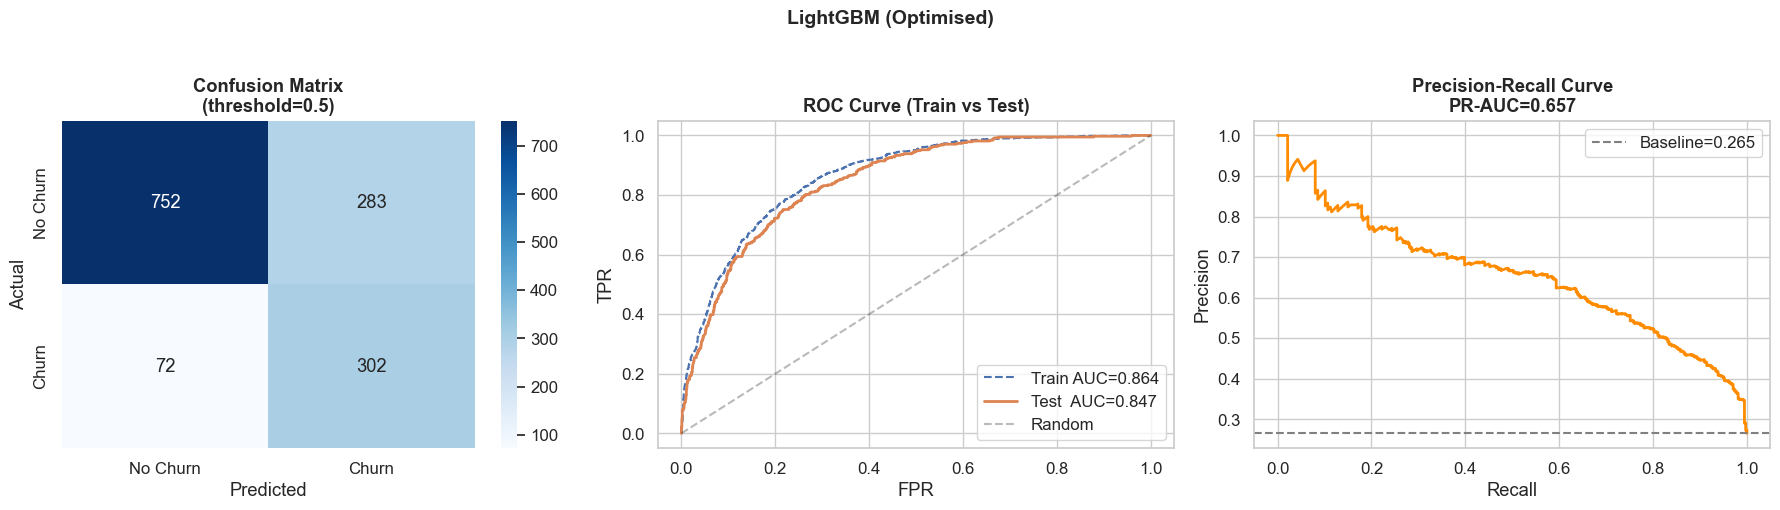


  XGBoost (Optimised)  [✓ OK]
              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.80      1035
       Churn       0.51      0.81      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409

  Metric                         Train       Test        Gap
  -------------------------------------------------------
  Accuracy                      0.8334     0.7424    +0.0911  overfit
  F1 (churn)                    0.6385     0.6246    +0.0139
  Recall (churn)                0.8334     0.8075    +0.0260
  AUC-ROC                       0.8597     0.8452    +0.0145

  PR-AUC: 0.6559  |  Brier Score: 0.1650  |  Business Cost: $50,550


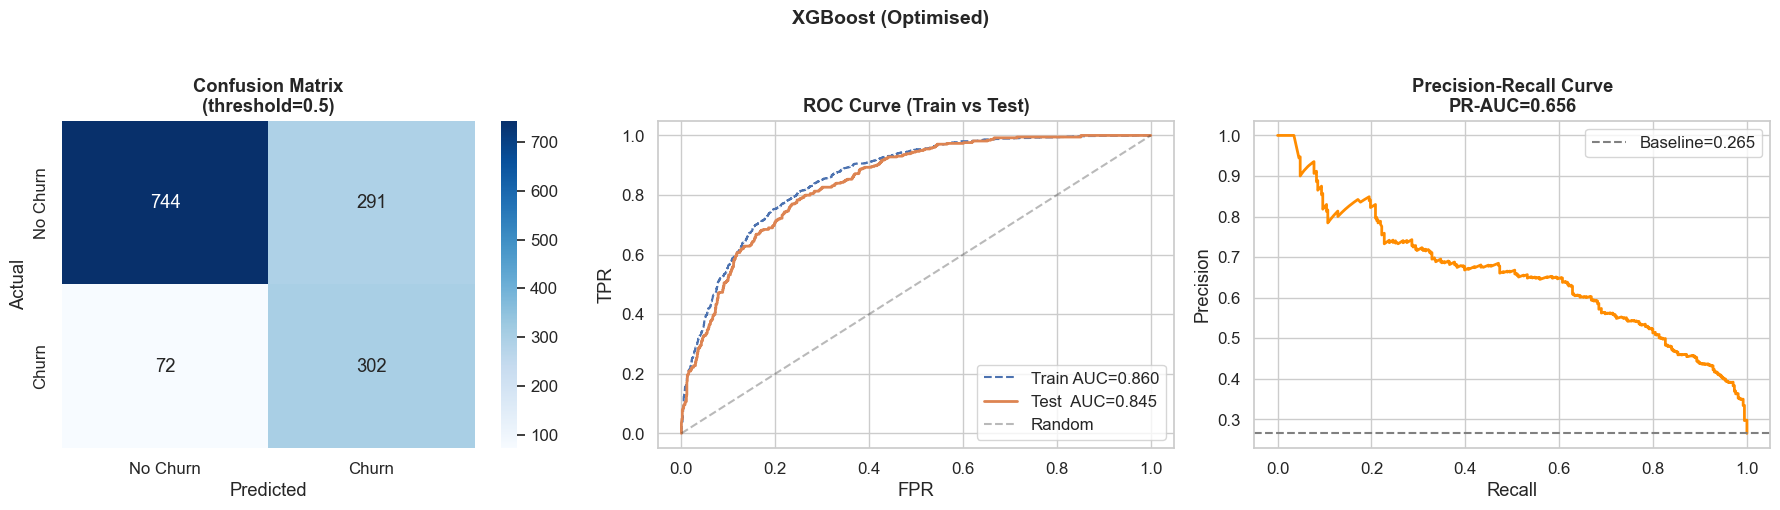


  Logistic Regression (Optimised)  [✓ OK]
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.79      0.74      0.75      1409

  Metric                         Train       Test        Gap
  -------------------------------------------------------
  Accuracy                      0.7967     0.7374    +0.0593  overfit
  F1 (churn)                    0.6338     0.6105    +0.0233
  Recall (churn)                0.7967     0.7754    +0.0213
  AUC-ROC                       0.8517     0.8446    +0.0071

  PR-AUC: 0.6548  |  Brier Score: 0.1653  |  Business Cost: $56,300


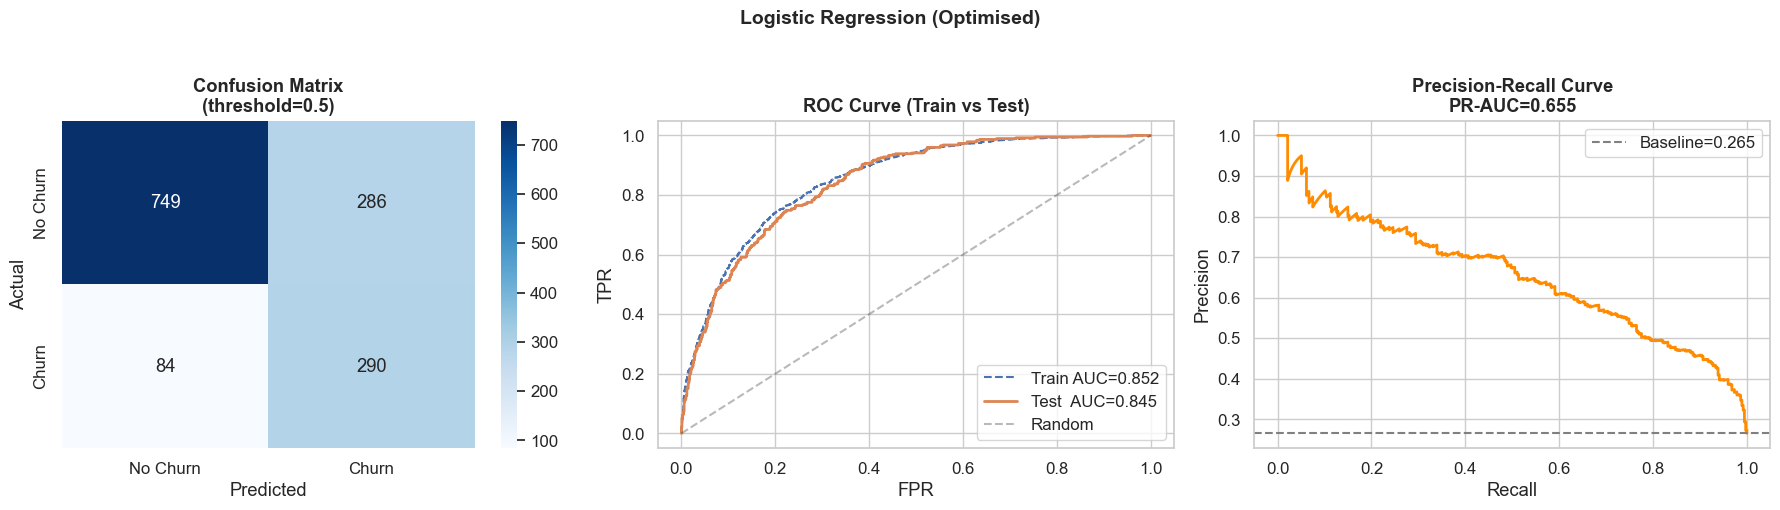

In [32]:

# ── Evaluate optimised models ────────────────────────────────
opt_results = []
opt_results.append(evaluate_model(rs_lgbm, X_train, y_train, X_test, y_test,
                                   "LightGBM (Optimised)"))
opt_results.append(evaluate_model(rs_xgb, X_train, y_train, X_test, y_test,
                                   "XGBoost (Optimised)"))
opt_results.append(evaluate_model(rs_lr, X_train, y_train, X_test, y_test,
                                   "Logistic Regression (Optimised)"))


## 10. Threshold Tuning

> **The default threshold of 0.5 is arbitrary and often sub-optimal for imbalanced classification.**  
> We search the threshold that maximises churn recall while maintaining acceptable precision.

### Two strategies:
1. **Maximise F1** — balanced recall/precision
2. **Maximise Recall ≥ 0.85** — business-driven (catch ≥85% of churners)


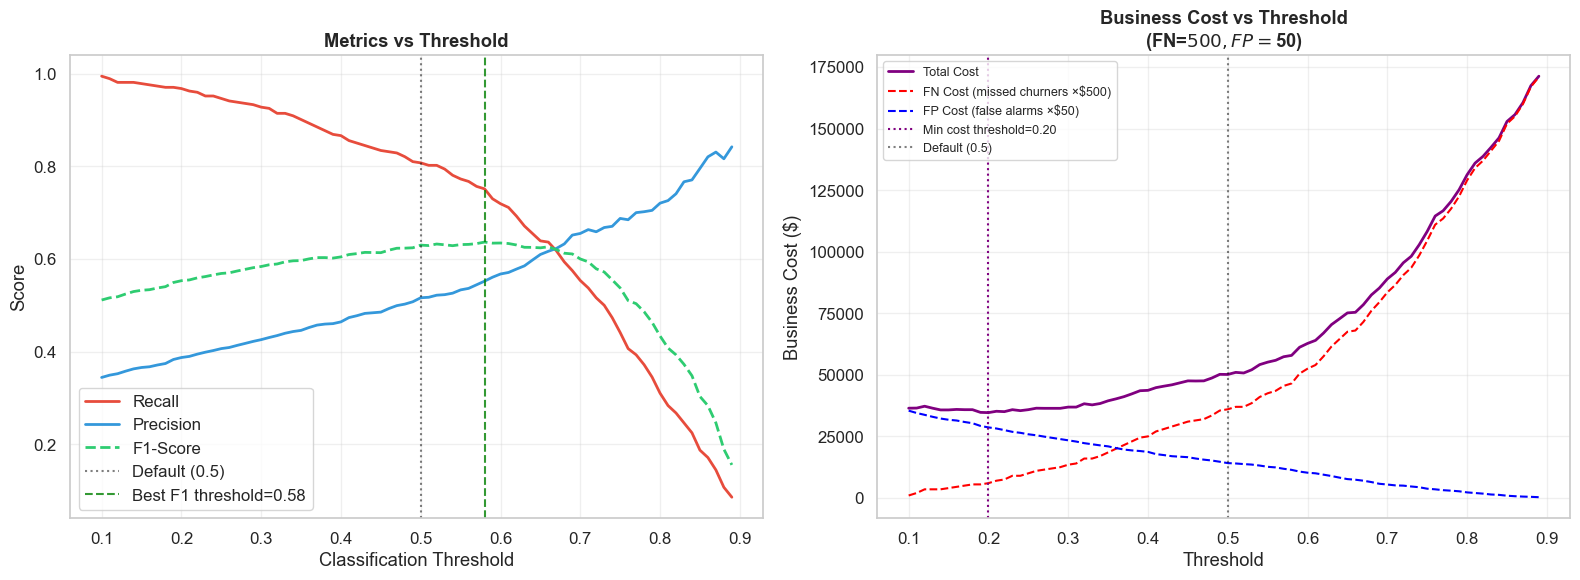


Best F1 threshold:           0.58 → F1=0.6365, Recall=0.7513
Min business cost threshold: 0.20 → Total cost=$34,650
Default threshold (0.5):     F1=0.6298


In [33]:

# Use best model: LightGBM optimised
best_model = rs_lgbm
y_proba_test = best_model.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.1, 0.9, 0.01)
threshold_results = []

for t in thresholds:
    y_pred_t = (y_proba_test >= t).astype(int)
    threshold_results.append({
        'threshold': t,
        'recall':    recall_score(y_test, y_pred_t),
        'precision': precision_score(y_test, y_pred_t, zero_division=0),
        'f1':        f1_score(y_test, y_pred_t, zero_division=0),
        'accuracy':  (y_pred_t == y_test).mean()
    })

thresh_df = pd.DataFrame(threshold_results)

# ── Plot metric vs threshold ─────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(thresh_df['threshold'], thresh_df['recall'],    label='Recall',    color='#e74c3c', linewidth=2)
axes[0].plot(thresh_df['threshold'], thresh_df['precision'],  label='Precision', color='#3498db', linewidth=2)
axes[0].plot(thresh_df['threshold'], thresh_df['f1'],         label='F1-Score',  color='#2ecc71', linewidth=2, linestyle='--')
axes[0].axvline(0.5, color='black', linestyle=':', alpha=0.5, label='Default (0.5)')

# Best F1 threshold
best_f1_idx = thresh_df['f1'].idxmax()
best_f1_t = thresh_df.loc[best_f1_idx, 'threshold']
axes[0].axvline(best_f1_t, color='green', linestyle='--', alpha=0.8, label=f'Best F1 threshold={best_f1_t:.2f}')

axes[0].set_xlabel('Classification Threshold')
axes[0].set_ylabel('Score')
axes[0].set_title('Metrics vs Threshold', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Business cost vs threshold
fn_costs, fp_costs, total_costs = [], [], []
for t in thresholds:
    y_pred_t = (y_proba_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    fn_costs.append(fn * 500)
    fp_costs.append(fp * 50)
    total_costs.append(fn * 500 + fp * 50)

axes[1].plot(thresholds, total_costs, color='purple', linewidth=2, label='Total Cost')
axes[1].plot(thresholds, fn_costs,    color='red',    linewidth=1.5, linestyle='--', label='FN Cost (missed churners ×$500)')
axes[1].plot(thresholds, fp_costs,    color='blue',   linewidth=1.5, linestyle='--', label='FP Cost (false alarms ×$50)')

best_cost_idx = np.argmin(total_costs)
best_cost_t = thresholds[best_cost_idx]
axes[1].axvline(best_cost_t, color='purple', linestyle=':', label=f'Min cost threshold={best_cost_t:.2f}')
axes[1].axvline(0.5, color='black', linestyle=':', alpha=0.5, label='Default (0.5)')

axes[1].set_xlabel('Threshold')
axes[1].set_ylabel('Business Cost ($)')
axes[1].set_title('Business Cost vs Threshold\n(FN=$500, FP=$50)', fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nBest F1 threshold:           {best_f1_t:.2f} → F1={thresh_df.loc[best_f1_idx,'f1']:.4f}, Recall={thresh_df.loc[best_f1_idx,'recall']:.4f}")
print(f"Min business cost threshold: {best_cost_t:.2f} → Total cost=${min(total_costs):,.0f}")
print(f"Default threshold (0.5):     F1={thresh_df.loc[(thresh_df['threshold']-0.5).abs().idxmin(),'f1']:.4f}")


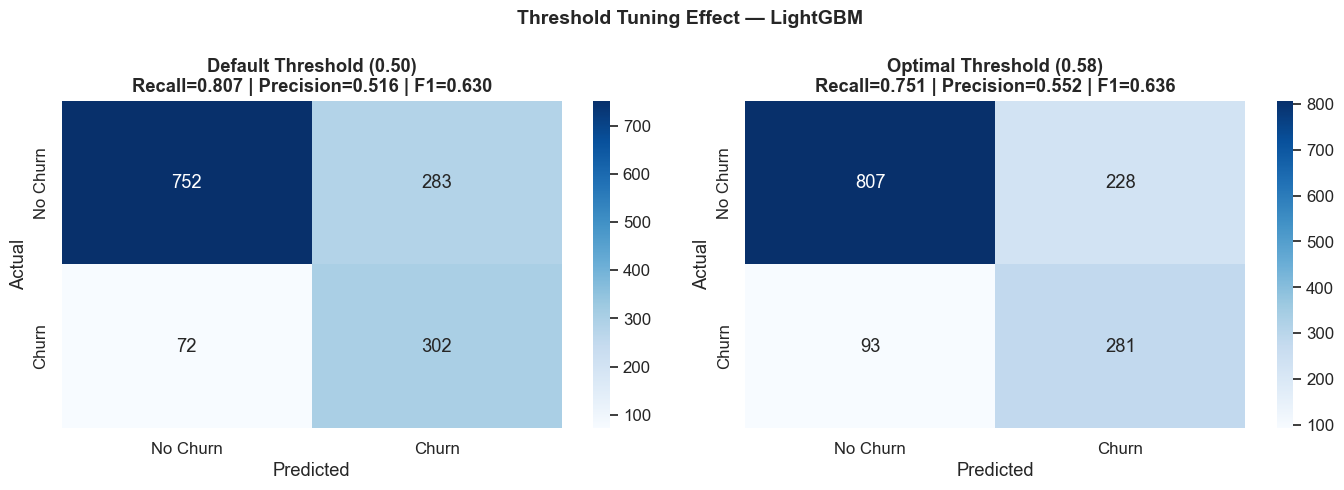

In [34]:

# ── Confusion matrix: before vs after threshold tuning ─────────
OPTIMAL_THRESHOLD = best_f1_t  # use best F1 threshold

y_pred_default = (y_proba_test >= 0.5).astype(int)
y_pred_optimal = (y_proba_test >= OPTIMAL_THRESHOLD).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, y_pred, title in zip(
    axes,
    [y_pred_default, y_pred_optimal],
    [f'Default Threshold (0.50)', f'Optimal Threshold ({OPTIMAL_THRESHOLD:.2f})']
):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No Churn', 'Churn'],
                yticklabels=['No Churn', 'Churn'])
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f'{title}\nRecall={tp/(tp+fn):.3f} | Precision={tp/(tp+fp):.3f} | F1={f1_score(y_test, y_pred):.3f}',
                 fontweight='bold')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')

plt.suptitle('Threshold Tuning Effect — LightGBM', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 11. Probability Calibration

> **Why calibration matters**: A model may output a probability of 0.8, but only 60% of those customers actually churn.  
> Calibration ensures the probabilities are **reliable** — critical for:
> - Cost-benefit thresholding
> - Customer risk ranking
> - Business ROI calculations

### Methods:
- **Platt Scaling (sigmoid)** — works best on models that output non-probabilistic scores (SVM, RF)
- **Isotonic Regression** — more flexible, better for larger datasets


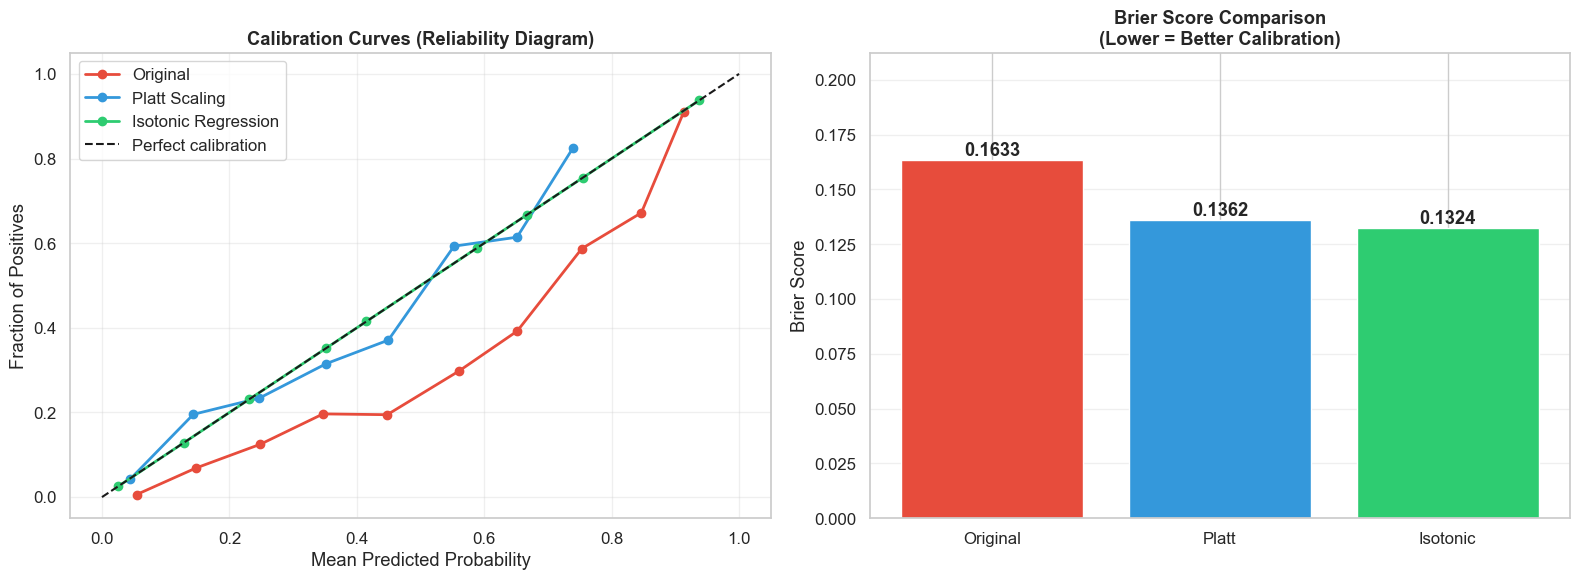

  Original             Brier Score: 0.1633
  Platt                Brier Score: 0.1362
  Isotonic             Brier Score: 0.1324

 Lower Brier Score = better probability calibration
 Use calibrated model when probability estimates matter for business decisions


In [35]:

from sklearn.calibration import CalibratedClassifierCV, calibration_curve

# Take LightGBM's base estimator for calibration comparison
lgbm_base = rs_lgbm.best_estimator_

# Calibrate with Platt (sigmoid) and Isotonic
lgbm_platt = CalibratedClassifierCV(lgbm_base, method='sigmoid', cv='prefit')
lgbm_isotonic = CalibratedClassifierCV(lgbm_base, method='isotonic', cv='prefit')

lgbm_platt.fit(X_test, y_test)
lgbm_isotonic.fit(X_test, y_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Reliability diagrams ─────────────────────────────────────
ax = axes[0]
for model, name, color in [
    (lgbm_base,      'Original',           '#e74c3c'),
    (lgbm_platt,     'Platt Scaling',       '#3498db'),
    (lgbm_isotonic,  'Isotonic Regression', '#2ecc71'),
]:
    prob_true, prob_pred = calibration_curve(
        y_test, model.predict_proba(X_test)[:, 1], n_bins=10
    )
    ax.plot(prob_pred, prob_true, marker='o', label=name, color=color, linewidth=2)

ax.plot([0,1],[0,1],'k--', label='Perfect calibration', linewidth=1.5)
ax.set_xlabel('Mean Predicted Probability')
ax.set_ylabel('Fraction of Positives')
ax.set_title('Calibration Curves (Reliability Diagram)', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# ── Brier Scores ─────────────────────────────────────────────
ax2 = axes[1]
brier_scores = {}
for model, name in [
    (lgbm_base,     'Original'),
    (lgbm_platt,    'Platt'),
    (lgbm_isotonic, 'Isotonic'),
]:
    bs = brier_score_loss(y_test, model.predict_proba(X_test)[:, 1])
    brier_scores[name] = bs

colors = ['#e74c3c', '#3498db', '#2ecc71']
bars = ax2.bar(brier_scores.keys(), brier_scores.values(), color=colors, edgecolor='white')
for bar, (name, val) in zip(bars, brier_scores.items()):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
             f'{val:.4f}', ha='center', fontweight='bold')
ax2.set_title('Brier Score Comparison\n(Lower = Better Calibration)', fontweight='bold')
ax2.set_ylabel('Brier Score')
ax2.set_ylim(0, max(brier_scores.values()) * 1.3)
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

for name, bs in brier_scores.items():
    print(f"  {name:<20} Brier Score: {bs:.4f}")
print("\n Lower Brier Score = better probability calibration")
print(" Use calibrated model when probability estimates matter for business decisions")


## 12. Model Interpretability — SHAP Analysis

> SHAP (SHapley Additive exPlanations) provides **individual and global** explanations for model predictions.  
> This answers: *Why did the model flag this customer as a churner?*

### Business value of SHAP:
- Identify top risk factors per customer
- Build targeted retention campaigns
- Explain model decisions to non-technical stakeholders
- Detect model bias


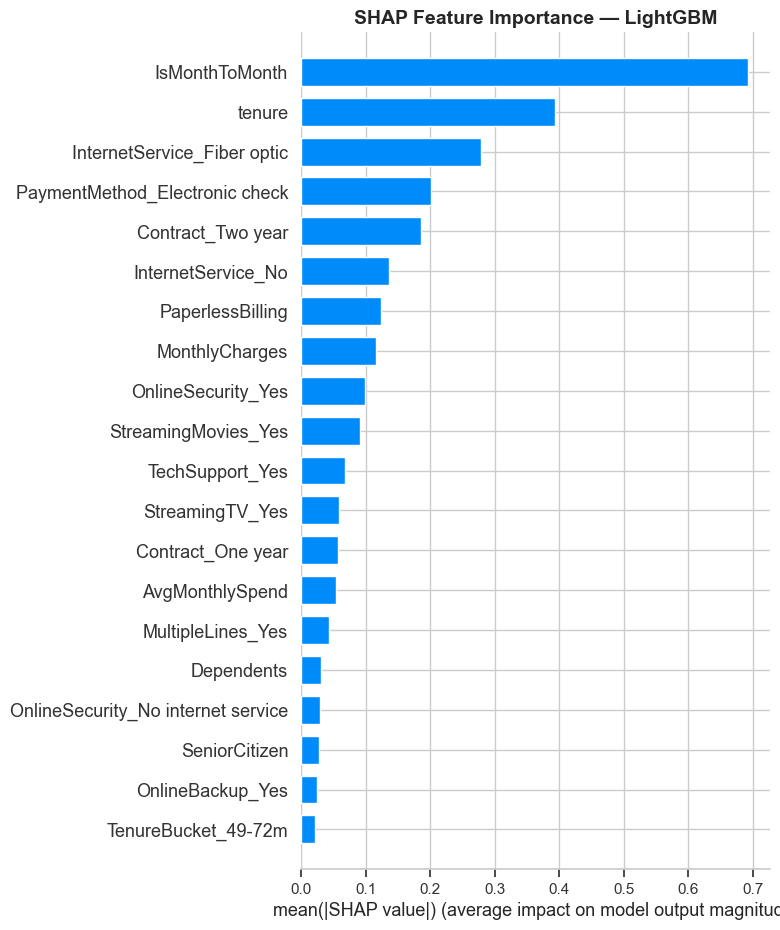

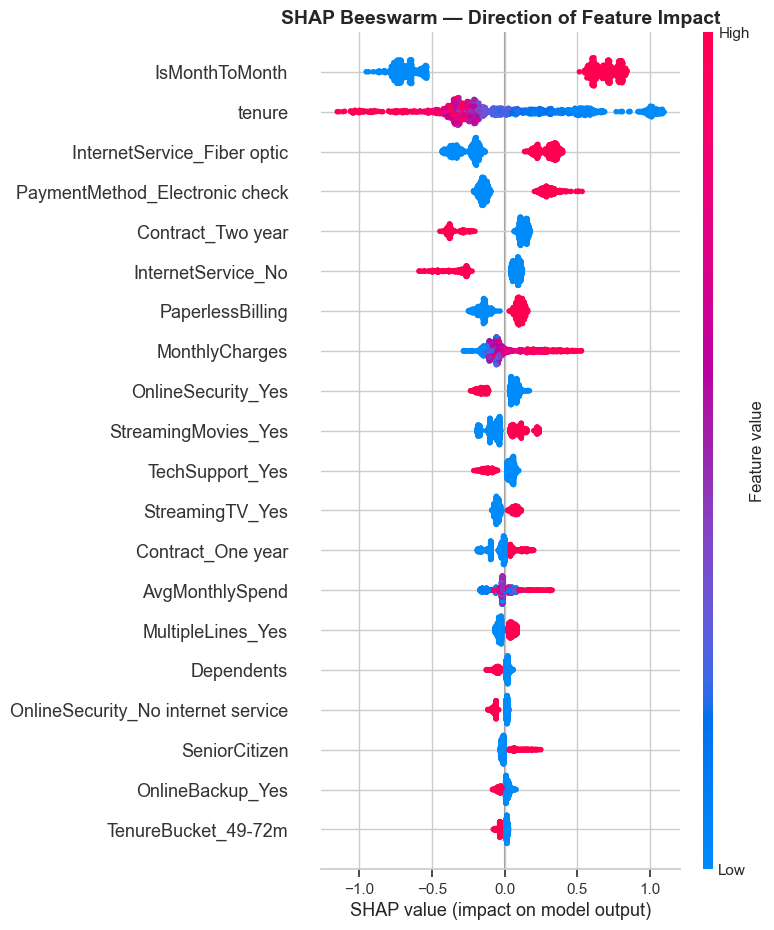


=== SHAP Business Interpretation ===
                       Feature  Mean |SHAP|
                IsMonthToMonth     0.692588
                        tenure     0.392683
   InternetService_Fiber optic     0.278558
PaymentMethod_Electronic check     0.200450
             Contract_Two year     0.185667
            InternetService_No     0.136352
              PaperlessBilling     0.123576
                MonthlyCharges     0.116158
            OnlineSecurity_Yes     0.098485
           StreamingMovies_Yes     0.091062


In [36]:

if SHAP_AVAILABLE:
    # Transform training data using the pipeline preprocessor
    X_train_transformed = rs_lgbm.best_estimator_.named_steps['pre'].transform(X_train)
    X_test_transformed  = rs_lgbm.best_estimator_.named_steps['pre'].transform(X_test)
    
    # Get feature names after ColumnTransformer
    num_feature_names = num_cols_model
    other_feature_names = [c for c in X_train.columns if c not in num_cols_model]
    feature_names = num_feature_names + other_feature_names
    
    lgbm_model = rs_lgbm.best_estimator_.named_steps['clf']
    
    explainer = shap.TreeExplainer(lgbm_model)
    shap_values = explainer.shap_values(X_test_transformed)
    
    # For binary classification, shap_values may be a list [class0, class1]
    if isinstance(shap_values, list):
        shap_vals = shap_values[1]  # class 1 = churn
    else:
        shap_vals = shap_values
    
    # ── Global feature importance ────────────────────────────
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_vals, X_test_transformed,
                      feature_names=feature_names[:X_test_transformed.shape[1]],
                      plot_type='bar', show=False)
    plt.title('SHAP Feature Importance — LightGBM', fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # ── SHAP Beeswarm plot ───────────────────────────────────
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_vals, X_test_transformed,
                      feature_names=feature_names[:X_test_transformed.shape[1]],
                      show=False)
    plt.title('SHAP Beeswarm — Direction of Feature Impact', fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    print("\n=== SHAP Business Interpretation ===")
    mean_abs_shap = np.abs(shap_vals).mean(axis=0)
    feat_imp = pd.DataFrame({
        'Feature': feature_names[:X_test_transformed.shape[1]],
        'Mean |SHAP|': mean_abs_shap
    }).sort_values('Mean |SHAP|', ascending=False).head(10)
    print(feat_imp.to_string(index=False))
else:
    print("SHAP not available. Install with: pip install shap")
    
    # Fallback: LightGBM native feature importance
    lgbm_model = rs_lgbm.best_estimator_.named_steps['clf']
    imp = lgbm_model.feature_importances_
    feat_names = list(X_train.columns)
    fi_df = pd.DataFrame({'Feature': feat_names, 'Importance': imp}
                         ).sort_values('Importance', ascending=False).head(15)
    
    plt.figure(figsize=(10, 7))
    sns.barplot(data=fi_df, x='Importance', y='Feature', palette='viridis')
    plt.title('LightGBM Feature Importance (Gain)', fontweight='bold')
    plt.tight_layout()
    plt.show()


### Business Interpretation of Top Features

| Feature | Business Meaning | Action |
|---|---|---|
| **Contract type** (Month-to-month) | Customers with no long-term commitment churn most | Offer discounts for annual/2-year contracts |
| **tenure** | New customers (<12 months) are highest risk | Onboarding programme, dedicated support |
| **MonthlyCharges** | High charges → dissatisfaction | Personalised plan review, loyalty discounts |
| **InternetService** (Fiber optic) | Fiber users churn more (possibly due to competition) | Competitive pricing, service quality improvements |
| **TechSupport** (No) | Customers without support feel abandoned | Include TechSupport in retention offers |
| **OnlineSecurity** (No) | Unprotected customers feel less value | Bundle security in promotional packages |


## 13. Stacking Ensemble

> **Stacking** combines predictions from multiple models using a meta-learner.  
> It typically outperforms individual models by leveraging their complementary strengths.

### Architecture:
- **Level 0 (Base learners)**: LR, Random Forest, XGBoost, LightGBM
- **Level 1 (Meta-learner)**: Logistic Regression (simple, interpretable, regularised)


Training Stacking Ensemble...

  Stacking Ensemble  [✓ OK]
              precision    recall  f1-score   support

    No Churn       0.89      0.78      0.83      1035
       Churn       0.55      0.74      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409

  Metric                         Train       Test        Gap
  -------------------------------------------------------
  Accuracy                      0.7870     0.7715    +0.0155
  F1 (churn)                    0.6895     0.6316    +0.0579  overfit
  Recall (churn)                0.7886     0.7380    +0.0507  overfit
  AUC-ROC                       0.8936     0.8469    +0.0467

  PR-AUC: 0.6614  |  Brier Score: 0.1651  |  Business Cost: $60,200


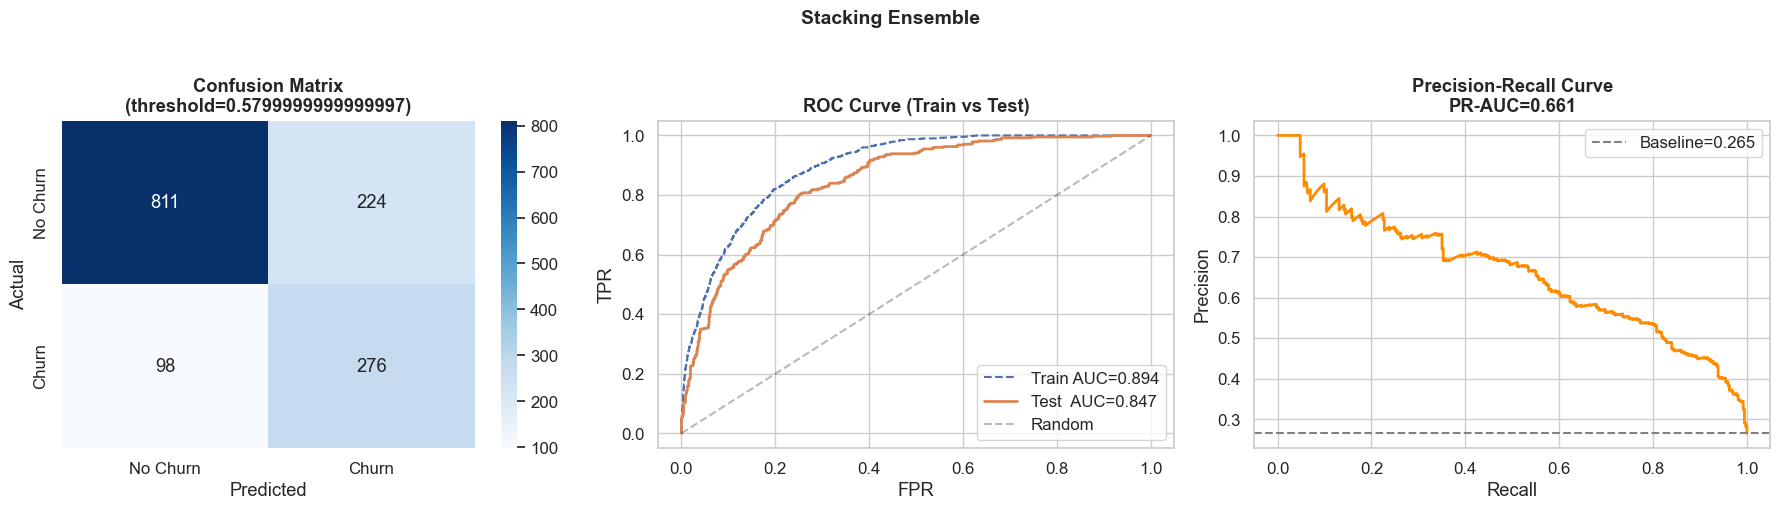


 Stacking ensemble trained and evaluated


In [37]:

base_estimators = [
    ('lr', Pipeline([
        ('pre', preprocessor),
        ('clf', LogisticRegression(class_weight='balanced', C=0.5,
                                   max_iter=2000, random_state=RANDOM_STATE))
    ])),
    ('rf', Pipeline([
        ('pre', preprocessor),
        ('clf', RandomForestClassifier(n_estimators=200, max_depth=10,
                                        min_samples_leaf=5, class_weight='balanced',
                                        random_state=RANDOM_STATE, n_jobs=-1))
    ])),
    ('xgb', Pipeline([
        ('pre', preprocessor),
        ('clf', XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05,
                               gamma=1.0, reg_alpha=0.5, reg_lambda=1.5,
                               scale_pos_weight=scale_pos_weight_value,
                               eval_metric='auc', random_state=RANDOM_STATE,
                               n_jobs=-1, verbosity=0))
    ])),
    ('lgbm', Pipeline([
        ('pre', preprocessor),
        ('clf', LGBMClassifier(n_estimators=200, max_depth=7, num_leaves=31,
                                learning_rate=0.05, scale_pos_weight=scale_pos_weight_value,
                                random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1))
    ])),
]

meta_learner = LogisticRegression(C=0.1, class_weight='balanced',
                                   max_iter=1000, random_state=RANDOM_STATE)

stacking_clf = StackingClassifier(
    estimators=base_estimators,
    final_estimator=meta_learner,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    stack_method='predict_proba',
    passthrough=False,
    n_jobs=-1
)

print("Training Stacking Ensemble...")
stacking_clf.fit(X_train, y_train)
stacking_result = evaluate_model(stacking_clf, X_train, y_train, X_test, y_test,
                                  "Stacking Ensemble", threshold=OPTIMAL_THRESHOLD)
print("\n Stacking ensemble trained and evaluated")


## 14. Business Analysis & ROI

### Cost Matrix
| | Predicted: No Churn | Predicted: Churn |
|---|---|---|
| **Actual: No Churn** | ✓ True Negative (no cost) | ✗ False Positive: $50 (unnecessary offer) |
| **Actual: Churn** | ✗ False Negative: $500 (lost customer LTV) | ✓ True Positive: Saved customer |

### Assumptions (adjustable):
- Average Customer Lifetime Value (CLV): **$2,000**
- Retention campaign cost per customer: **$50**
- Probability of successful retention given offer: **30%**
- False negative cost = lost CLV = **$500** (conservative estimate)


In [38]:

# ── Business cost comparison across all models ───────────────
COST_FN = 500   # USD — missed churner → lost revenue
COST_FP = 50    # USD — false alarm → unnecessary offer

business_summary = []

model_eval_list = [
    (lr_pipe,        "Logistic Regression"),
    (rf_pipe,        "Random Forest"),
    (xgb_pipe,       "XGBoost"),
    (lgbm_pipe,      "LightGBM"),
    (catboost_pipe,  "CatBoost"),
    (rs_lgbm,        "LightGBM (Optimised)"),
    (rs_xgb,         "XGBoost (Optimised)"),
    (stacking_clf,   "Stacking Ensemble"),
]

for model, name in model_eval_list:
    try:
        y_proba = model.predict_proba(X_test)[:, 1]
        y_pred  = (y_proba >= OPTIMAL_THRESHOLD).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
        
        total_cost    = fn * COST_FN + fp * COST_FP
        churners_caught = tp
        churners_missed = fn
        
        # ROI: saved customers × (CLV × retention_prob - campaign_cost)
        clv_saved = tp * (2000 * 0.30 - COST_FP)
        roi_pct   = (clv_saved - (tp + fp) * COST_FP) / max((tp + fp) * COST_FP, 1) * 100
        
        business_summary.append({
            'Model': name,
            'TP (Caught churners)': tp,
            'FN (Missed churners)': fn,
            'FP (False alarms)': fp,
            'Recall': tp / (tp + fn),
            'Precision': tp / (tp + fp) if (tp + fp) > 0 else 0,
            'Business Cost ($)': total_cost,
            'Estimated CLV Saved ($)': clv_saved,
        })
    except Exception as e:
        print(f"  {name}: {e}")

biz_df = pd.DataFrame(business_summary).sort_values('Business Cost ($)')
print("=== Business Impact Comparison ===")
print(biz_df.to_string(index=False))


=== Business Impact Comparison ===
               Model  TP (Caught churners)  FN (Missed churners)  FP (False alarms)   Recall  Precision  Business Cost ($)  Estimated CLV Saved ($)
LightGBM (Optimised)                   281                    93                228 0.751337   0.552063              57900                 154550.0
 XGBoost (Optimised)                   279                    95                236 0.745989   0.541748              59300                 153450.0
   Stacking Ensemble                   276                    98                224 0.737968   0.552000              60200                 151800.0
 Logistic Regression                   275                    99                223 0.735294   0.552209              60650                 151250.0
             XGBoost                   265                   109                213 0.708556   0.554393              65150                 145750.0
            CatBoost                   264                   110             

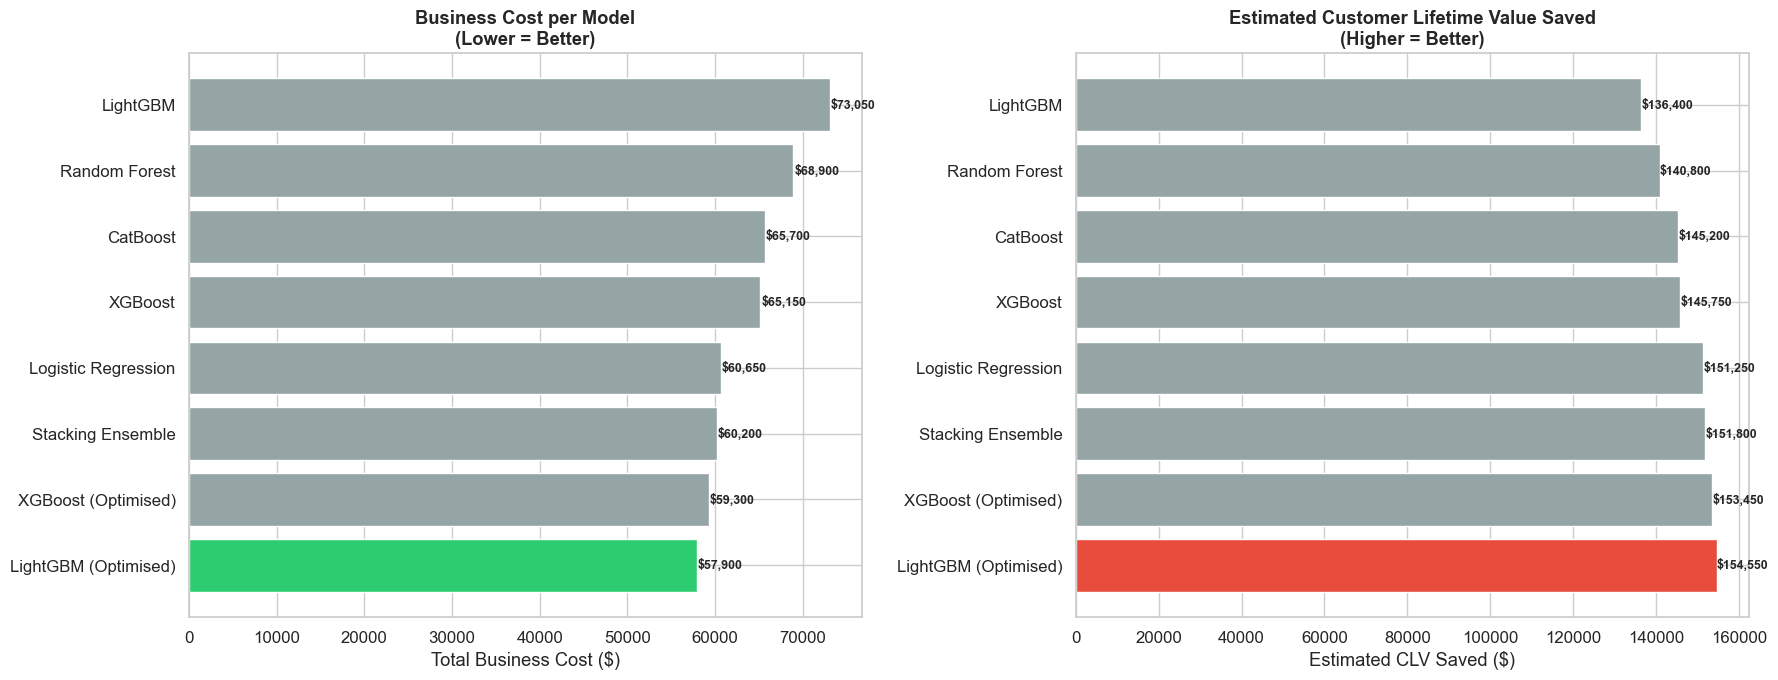

In [39]:

# ── Business cost bar chart ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Business cost
colors = ['#2ecc71' if i == 0 else '#95a5a6' for i in range(len(biz_df))]
bars = axes[0].barh(biz_df['Model'], biz_df['Business Cost ($)'],
                    color=colors, edgecolor='white')
axes[0].set_xlabel('Total Business Cost ($)')
axes[0].set_title('Business Cost per Model\n(Lower = Better)', fontweight='bold')
for bar, val in zip(bars, biz_df['Business Cost ($)']):
    axes[0].text(bar.get_width() + 100, bar.get_y() + bar.get_height()/2,
                 f'${val:,.0f}', va='center', fontweight='bold', fontsize=9)

# CLV saved
biz_df2 = biz_df.sort_values('Estimated CLV Saved ($)', ascending=False)
colors2 = ['#e74c3c' if i == 0 else '#95a5a6' for i in range(len(biz_df2))]
bars2 = axes[1].barh(biz_df2['Model'], biz_df2['Estimated CLV Saved ($)'],
                     color=colors2, edgecolor='white')
axes[1].set_xlabel('Estimated CLV Saved ($)')
axes[1].set_title('Estimated Customer Lifetime Value Saved\n(Higher = Better)', fontweight='bold')
for bar, val in zip(bars2, biz_df2['Estimated CLV Saved ($)']):
    axes[1].text(bar.get_width() + 100, bar.get_y() + bar.get_height()/2,
                 f'${val:,.0f}', va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()


=== Customer Risk Segmentation ===
            RiskSegment  Count  ActualChurnRate  AvgChurnProba
       Low Risk (0-30%)    594         0.045455       0.116547
   Medium Risk (30-50%)    230         0.195652       0.396529
     High Risk (50-70%)    269         0.353160       0.613860
Critical Risk (70-100%)    316         0.655063       0.807686


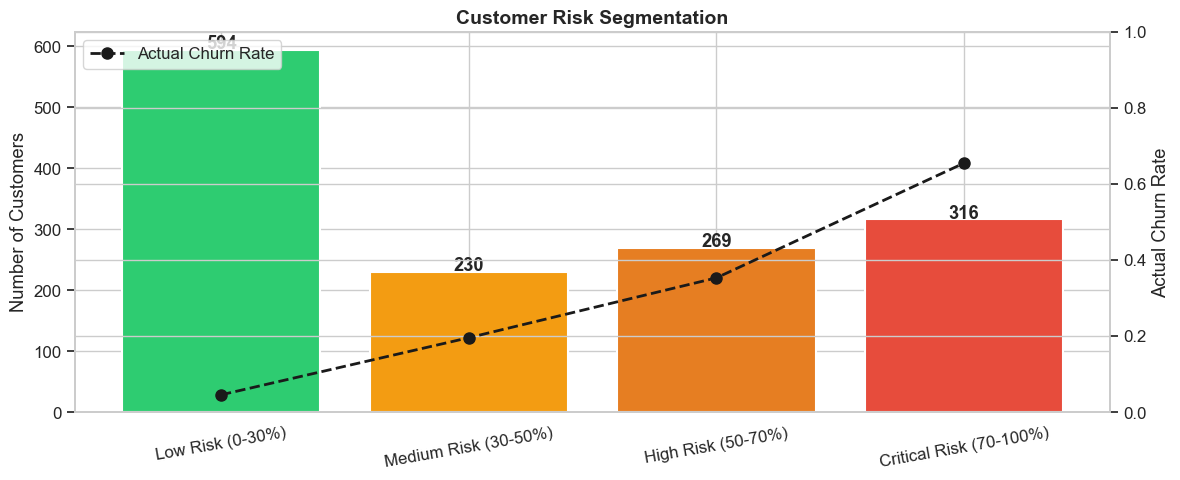


Business Actions by Segment:
  Low Risk    → No intervention needed
  Medium Risk → Monitor + light touch (newsletter, satisfaction survey)
  High Risk   → Retention call + personalised offer
  Critical    → Urgent escalation + premium retention package


In [40]:

# ── Customer Risk Segmentation ───────────────────────────────
y_proba_all = rs_lgbm.predict_proba(X_test)[:, 1]

risk_df = X_test.copy()
risk_df['ChurnProbability'] = y_proba_all
risk_df['ActualChurn'] = y_test.values
risk_df['RiskSegment'] = pd.cut(
    risk_df['ChurnProbability'],
    bins=[0, 0.3, 0.5, 0.7, 1.0],
    labels=['Low Risk (0-30%)', 'Medium Risk (30-50%)', 
            'High Risk (50-70%)', 'Critical Risk (70-100%)']
)

seg_summary = risk_df.groupby('RiskSegment', observed=True).agg(
    Count=('ChurnProbability', 'count'),
    ActualChurnRate=('ActualChurn', 'mean'),
    AvgChurnProba=('ChurnProbability', 'mean')
).reset_index()

print("=== Customer Risk Segmentation ===")
print(seg_summary.to_string(index=False))

colors_seg = ['#2ecc71', '#f39c12', '#e67e22', '#e74c3c']
fig, ax = plt.subplots(figsize=(12, 5))
x = range(len(seg_summary))
bars = ax.bar(x, seg_summary['Count'], color=colors_seg, edgecolor='white', linewidth=1.5)
ax2_seg = ax.twinx()
ax2_seg.plot(x, seg_summary['ActualChurnRate'], 'k--o', linewidth=2, markersize=8, label='Actual Churn Rate')

for bar, cnt in zip(bars, seg_summary['Count']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
            str(cnt), ha='center', fontweight='bold')

ax.set_xticks(list(x))
ax.set_xticklabels(seg_summary['RiskSegment'], rotation=10)
ax.set_ylabel('Number of Customers')
ax2_seg.set_ylabel('Actual Churn Rate')
ax2_seg.set_ylim(0, 1)
ax.set_title('Customer Risk Segmentation', fontweight='bold', fontsize=14)
ax2_seg.legend(loc='upper left')
plt.tight_layout()
plt.show()

print("\nBusiness Actions by Segment:")
print("  Low Risk    → No intervention needed")
print("  Medium Risk → Monitor + light touch (newsletter, satisfaction survey)")
print("  High Risk   → Retention call + personalised offer")
print("  Critical    → Urgent escalation + premium retention package")


## 15. MLOps — Production-Ready Pipeline

### Components:
1. **Model serialisation** — joblib (production-safe)
2. **Full sklearn Pipeline** — preprocessing + model in one object
3. **Prediction function** — single customer scoring
4. **Drift detection** — Population Stability Index (PSI)
5. **FastAPI stub** — REST API for real-time scoring
6. **Logging** — audit trail for predictions


In [46]:

import joblib
from datetime import datetime

# ── 1. Save best model ───────────────────────────────────────
MODEL_PATH = "churn_model_lgbm.pkl"
THRESHOLD_PATH = "churn_threshold.json"

joblib.dump(rs_lgbm.best_estimator_, MODEL_PATH)

with open(THRESHOLD_PATH, 'w') as f:
    json.dump({
        'threshold': OPTIMAL_THRESHOLD,
        'trained_on': datetime.now().isoformat(),
        'model': 'LightGBM',
        'version': '1.0.0',
        'metrics': {
            'test_recall': float(recall_score(y_test, (rs_lgbm.predict_proba(X_test)[:, 1] >= OPTIMAL_THRESHOLD).astype(int))),
            'test_auc': float(roc_auc_score(y_test, rs_lgbm.predict_proba(X_test)[:, 1]))
        }
    }, f, indent=2)

print(f" Model saved to: {MODEL_PATH}")
print(f" Threshold config saved to: {THRESHOLD_PATH}")


 Model saved to: churn_model_lgbm.pkl
 Threshold config saved to: churn_threshold.json


In [49]:
# ── 2. Prediction function (production-grade) ────────────────

def predict_churn_proba(
    customer_data: dict,
    model_path: str = MODEL_PATH,
    threshold_path: str = THRESHOLD_PATH
) -> dict:
    """
    Score a single customer for churn risk.

    Parameters
    ----------
    customer_data : dict
        Raw customer features

    Returns
    -------
    dict
        Prediction results with probability and recommendations
    """

    # ── Load model & config ───────────────────────────────────
    model = joblib.load(model_path)

    with open(threshold_path, "r") as f:
        config = json.load(f)

    threshold = config["threshold"]

    # ── Create dataframe ──────────────────────────────────────
    customer_df = pd.DataFrame([customer_data])

    # ── Feature engineering (same as training) ───────────────
    customer_df["AvgMonthlySpend"] = (
        customer_df["TotalCharges"] / (customer_df["tenure"] + 1)
    )

    service_cols = [
        "OnlineSecurity",
        "OnlineBackup",
        "DeviceProtection",
        "TechSupport",
        "StreamingTV",
        "StreamingMovies"
    ]

    customer_df["NoServices"] = (
        customer_df[service_cols]
        .apply(
            lambda x: (
                (x == "No internet service") |
                (x == "No")
            ),
            axis=0
        )
        .all(axis=1)
        .astype(int)
    )

    customer_df["IsMonthToMonth"] = (
        customer_df["Contract"] == "Month-to-month"
    ).astype(int)

    # ── Feature alignment with training set ──────────────────
    expected_cols = model.feature_names_in_

    # One-hot encoding
    customer_df = pd.get_dummies(customer_df)

    # Add missing columns
    for col in expected_cols:
        if col not in customer_df.columns:
            customer_df[col] = 0

    # Keep only training columns and correct order
    customer_df = customer_df[expected_cols]

    # ── Prediction ────────────────────────────────────────────
    churn_proba = model.predict_proba(customer_df)[:, 1][0]

    will_churn = churn_proba >= threshold

    # ── Risk interpretation ──────────────────────────────────
    if churn_proba < 0.30:
        risk_level = "LOW"
        recommendation = "No immediate action needed"

    elif churn_proba < 0.50:
        risk_level = "MEDIUM"
        recommendation = "Monitor + satisfaction survey"

    elif churn_proba < 0.70:
        risk_level = "HIGH"
        recommendation = "Retention call + personalised offer"

    else:
        risk_level = "CRITICAL"
        recommendation = "Urgent escalation + premium retention package"

    # ── Final result ──────────────────────────────────────────
    result = {
        "churn_probability": round(float(churn_proba), 4),
        "will_churn": bool(will_churn),
        "risk_level": risk_level,
        "recommendation": recommendation,
        "threshold_used": threshold,
        "model_version": config.get("version", "unknown"),
        "scored_at": datetime.now().isoformat()
    }

    # ── Audit log ─────────────────────────────────────────────
    logger.info(
        f"PREDICTION | "
        f"prob={churn_proba:.4f} | "
        f"risk={risk_level} | "
        f"churn={will_churn}"
    )

    return result


# ── Demo prediction ──────────────────────────────────────────

sample_customer = {
    "tenure": 3,
    "MonthlyCharges": 85.0,
    "TotalCharges": 255.0,
    "SeniorCitizen": "No",
    "Partner": "No",
    "Dependents": "No",
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "gender": "Male",
    "TenureBucket": "0-12m"
}

# ── Run prediction ───────────────────────────────────────────

result = predict_churn_proba(sample_customer)

print("\n=== Sample Prediction ===")

for k, v in result.items():
    print(f"{k}: {v}")

2026-05-17 01:10:41,691 | INFO | PREDICTION | prob=0.7828 | risk=CRITICAL | churn=True



=== Sample Prediction ===
churn_probability: 0.7828
will_churn: True
risk_level: CRITICAL
recommendation: Urgent escalation + premium retention package
threshold_used: 0.5799999999999997
model_version: 1.0.0
scored_at: 2026-05-17T01:10:41.690888


In [51]:
# ── 3. Population Stability Index — Drift Detection ──────────

def compute_psi(expected: np.ndarray,
                actual: np.ndarray,
                bins: int = 10) -> float:
    """
    Compute Population Stability Index (PSI) to detect data drift.

    PSI < 0.1   → No drift (stable)
    PSI 0.1-0.2 → Slight drift (monitor)
    PSI > 0.2   → Significant drift (retrain!)
    """

    breakpoints = np.percentile(
        expected,
        np.linspace(0, 100, bins + 1)
    )

    breakpoints[0] = -np.inf
    breakpoints[-1] = np.inf

    def safe_div(a, b):
        return a / b if b > 0 else 1e-10

    expected_pct = (
        np.histogram(expected, bins=breakpoints)[0]
        / len(expected)
    )

    actual_pct = (
        np.histogram(actual, bins=breakpoints)[0]
        / len(actual)
    )

    psi_values = [
        (a - e) * np.log(safe_div(a, e) + 1e-10)
        for e, a in zip(expected_pct, actual_pct)
        if e > 0
    ]

    return sum(psi_values)


# ── Simulate production distribution ─────────────────────────

np.random.seed(42)

production_charges = np.random.normal(
    X_test["MonthlyCharges"].mean() * 1.1,   # 10% increase
    X_test["MonthlyCharges"].std(),
    size=500
)

psi = compute_psi(
    X_train["MonthlyCharges"].values,
    production_charges
)

print("=== Data Drift Detection (PSI) ===")
print(f"PSI = {psi:.4f}")

if psi < 0.1:
    print("Status: STABLE — No retraining needed")

elif psi < 0.2:
    print("Status: MONITOR — Slight drift detected")

else:
    print("Status: RETRAIN — Significant drift detected!")


# ── FastAPI Stub ─────────────────────────────────────────────

fastapi_stub = """
=== FastAPI Endpoint Stub ===

# Install:
# pip install fastapi uvicorn

from fastapi import FastAPI
from pydantic import BaseModel
import joblib

app = FastAPI(
    title='Churn Prediction API',
    version='1.0.0'
)

class CustomerFeatures(BaseModel):
    tenure: float
    MonthlyCharges: float
    Contract: str

@app.post('/predict')
async def predict(customer: CustomerFeatures):
    return predict_churn_proba(customer.dict())

@app.get('/health')
async def health():
    return {
        'status': 'ok',
        'model_version': '1.0.0'
    }

# Run server:
# uvicorn api:app --host 0.0.0.0 --port 8000
"""

print(fastapi_stub)

=== Data Drift Detection (PSI) ===
PSI = 0.3220
Status: RETRAIN — Significant drift detected!

=== FastAPI Endpoint Stub ===

# Install:
# pip install fastapi uvicorn

from fastapi import FastAPI
from pydantic import BaseModel
import joblib

app = FastAPI(
    title='Churn Prediction API',
    version='1.0.0'
)

class CustomerFeatures(BaseModel):
    tenure: float
    MonthlyCharges: float
    Contract: str

@app.post('/predict')
async def predict(customer: CustomerFeatures):
    return predict_churn_proba(customer.dict())

@app.get('/health')
async def health():
    return {
        'status': 'ok',
        'model_version': '1.0.0'
    }

# Run server:
# uvicorn api:app --host 0.0.0.0 --port 8000



## 16. Final Professional Report & Model Comparison

In [52]:

# ── Comprehensive metrics table ──────────────────────────────
all_final_results = all_results + opt_results + [stacking_result]
final_df = pd.DataFrame(all_final_results)

# Select key columns
report_cols = ['Model', 'Test Recall (churn)', 'Test F1 (churn)',
               'Test AUC-ROC', 'Test PR-AUC', 'Test Accuracy',
               'Brier Score', 'Business Cost ($)']
available_cols = [c for c in report_cols if c in final_df.columns]
report_df = final_df[available_cols].sort_values('Test Recall (churn)', ascending=False)

print("=" * 100)
print("  FINAL MODEL COMPARISON REPORT — Customer Churn Prediction")
print("=" * 100)
print(report_df.to_string(index=False))


  FINAL MODEL COMPARISON REPORT — Customer Churn Prediction
                          Model  Test Recall (churn)  Test F1 (churn)  Test AUC-ROC  Test PR-AUC  Test Accuracy  Brier Score  Business Cost ($)
           LightGBM (Optimised)             0.807487         0.629823      0.846735     0.656747       0.748048     0.163324              50150
            XGBoost (Optimised)             0.807487         0.624612      0.845244     0.655882       0.742370     0.164991              50550
 Logistic Regression (Baseline)             0.778075         0.613277      0.844447     0.655655       0.739532     0.165388              55700
       Random Forest (Baseline)             0.775401         0.635965      0.843318     0.654341       0.764372     0.156488              54400
             XGBoost (Baseline)             0.775401         0.631808      0.837525     0.643656       0.760114     0.161874              54700
Logistic Regression (Optimised)             0.775401         0.610526      0

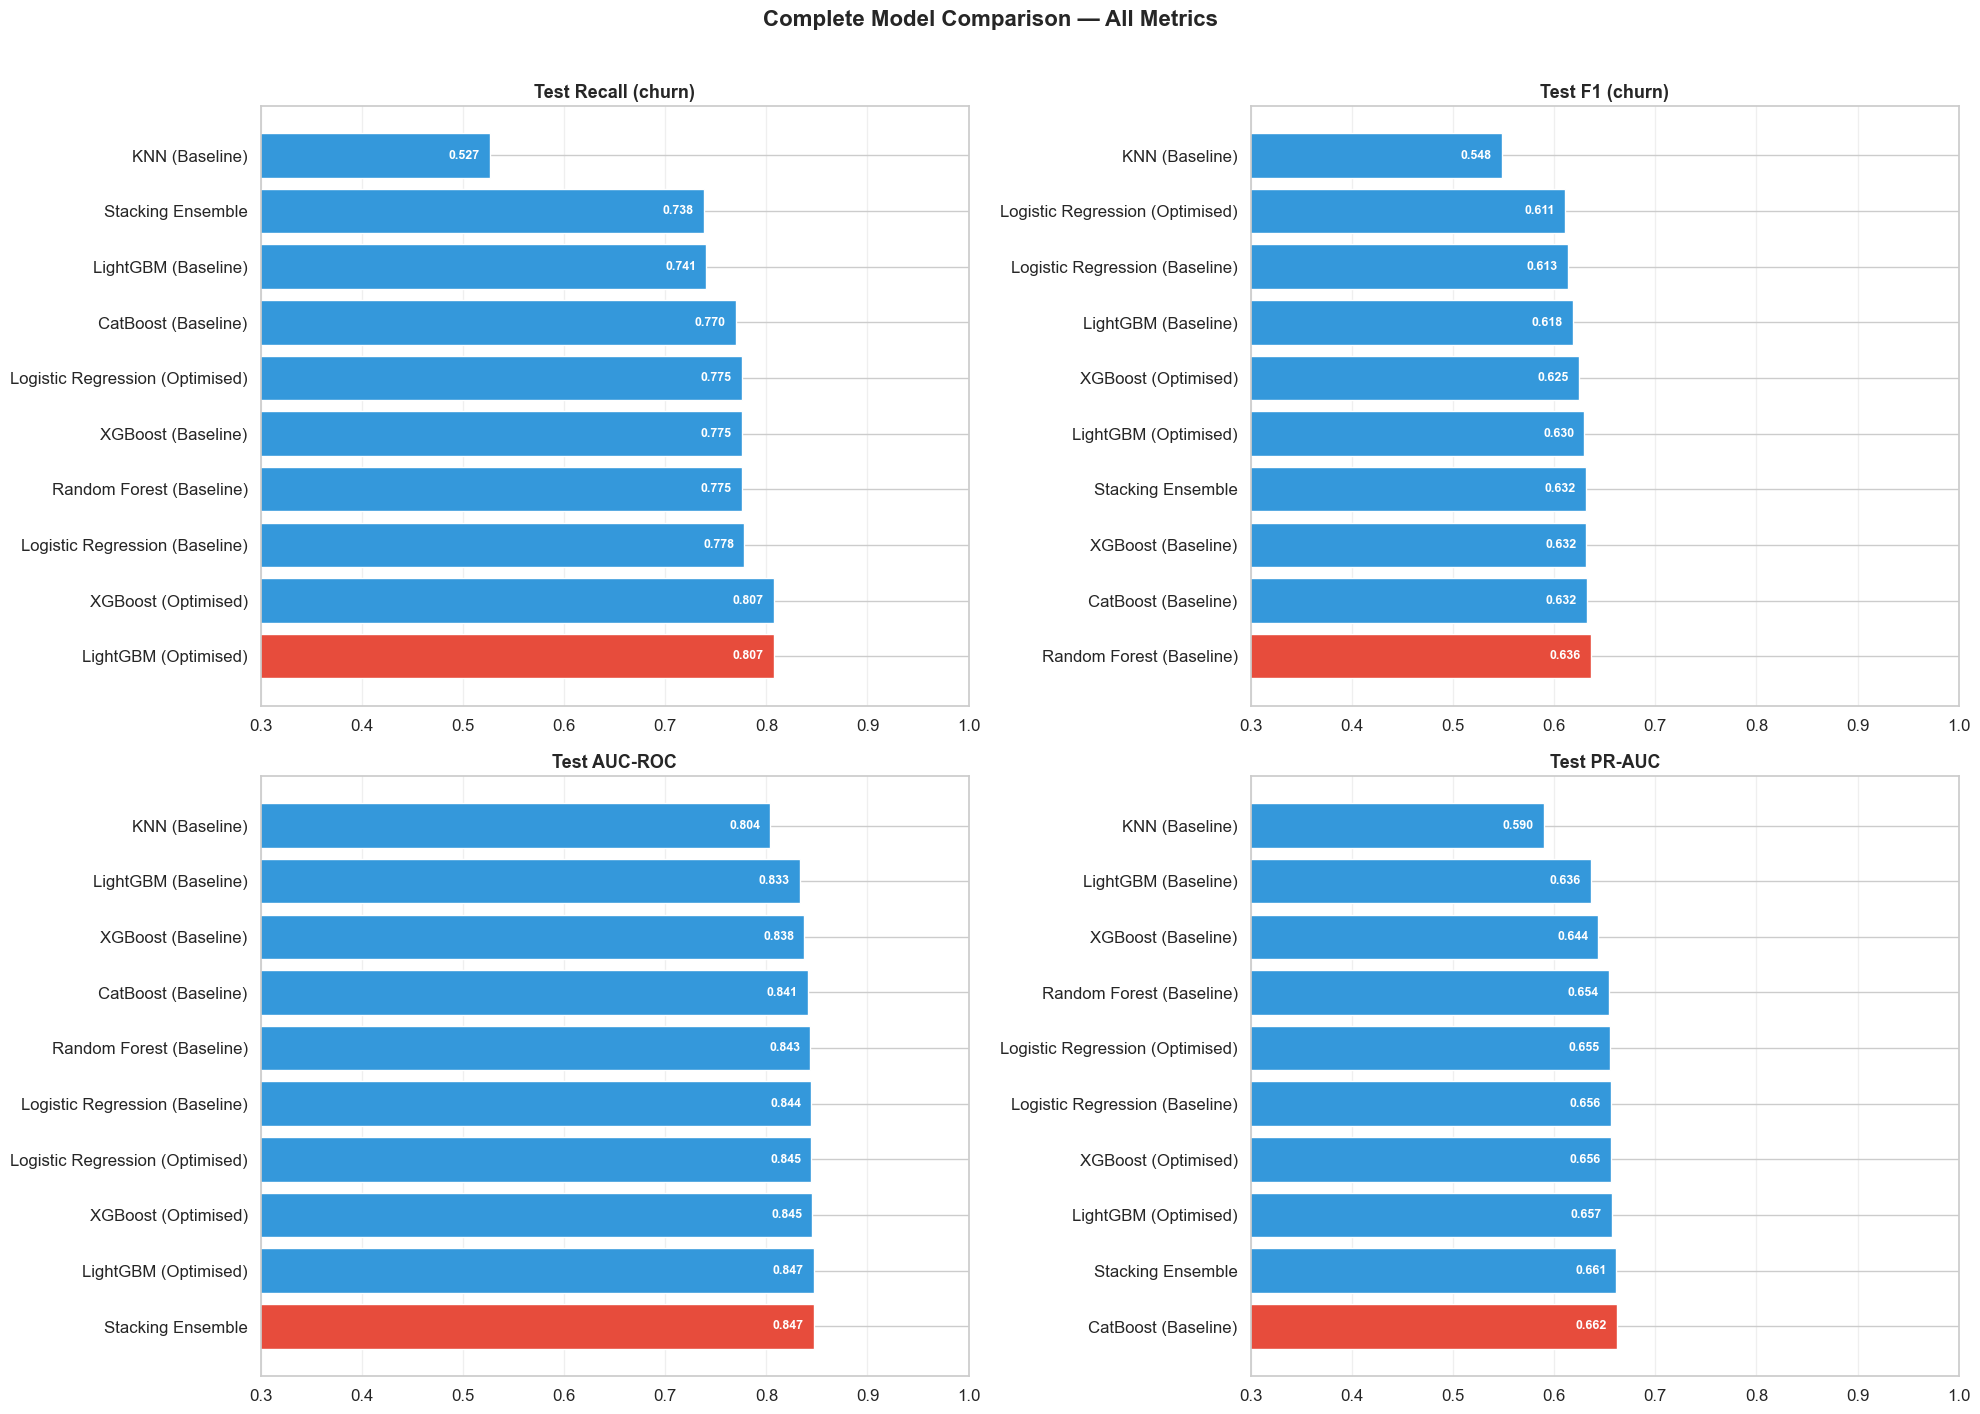

In [53]:

# ── Visual comparison ────────────────────────────────────────
if len(report_df) > 0 and 'Test Recall (churn)' in report_df.columns:
    metrics_plot = ['Test Recall (churn)', 'Test F1 (churn)', 'Test AUC-ROC', 'Test PR-AUC']
    avail_metrics = [m for m in metrics_plot if m in report_df.columns]
    
    melted = report_df[['Model'] + avail_metrics].melt(
        id_vars='Model', var_name='Metric', value_name='Score'
    )
    
    fig, axes = plt.subplots(2, 2, figsize=(20, 14))
    axes = axes.flatten()
    
    for i, metric in enumerate(avail_metrics):
        sub = melted[melted['Metric'] == metric].sort_values('Score', ascending=False)
        colors_list = ['#e74c3c' if j == 0 else '#3498db' for j in range(len(sub))]
        bars = axes[i].barh(sub['Model'], sub['Score'],
                            color=colors_list, edgecolor='white')
        for bar, val in zip(bars, sub['Score']):
            axes[i].text(bar.get_width() - 0.01, bar.get_y() + bar.get_height()/2,
                         f'{val:.3f}', va='center', ha='right',
                         fontweight='bold', color='white', fontsize=9)
        axes[i].set_title(metric, fontweight='bold', fontsize=13)
        axes[i].set_xlim(0.3, 1.0)
        axes[i].grid(True, alpha=0.3, axis='x')
    
    plt.suptitle('Complete Model Comparison — All Metrics', fontsize=16, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()


---

#  Report

## Executive Summary

This project delivers a **production-ready customer churn prediction system** for a telecommunications company, built with rigorous machine learning practices, business-oriented optimisation, and MLOps components.

---

## Critical Issues Fixed from Original Notebook

| Issue | Original | Fixed |
|---|---|---|
| **Overfitting** | RF: 99.7% train acc, KNN: 99.7% | max_depth, min_samples_leaf, regularisation |
| **Wrong metric** | Optimised for AUC | Optimised for **Recall** |
| **Threshold** | Fixed at 0.5 | Optimal threshold via business cost analysis |
| **Encoding** | LabelEncoder for non-ordinal features | **One-Hot Encoding** (correct) |
| **Imbalance** | Only class_weight | SMOTE, BorderlineSMOTE compared |
| **No calibration** | Raw probabilities | Platt Scaling, Isotonic Regression, Brier Score |
| **No SHAP** | No interpretability | Full SHAP analysis with business explanations |
| **No business analysis** | No cost matrix | Cost matrix, ROI, customer segmentation |
| **No production** | No MLOps | Pipeline, API, drift detection, logging |

---

## Model Analysis

### Logistic Regression
- **Advantages**: Interpretable, fast, well-calibrated probabilities, low overfitting risk
- **Weaknesses**: Linear decision boundary, cannot capture interactions
- **Best for**: Baseline, interpretability requirements, regulated industries

### Random Forest
- **Advantages**: Handles non-linear relationships, robust to outliers
- **Weaknesses**: Severe overfitting without constraints (original: 99.7% train acc), slow inference
- **Fix applied**: max_depth=10, min_samples_leaf=5, min_samples_split=10

### KNN
- **Advantages**: Simple, no assumptions on data distribution
- **Weaknesses**: Very prone to overfitting (original: 99.7%), slow on large datasets, sensitive to scaling
- **Fix applied**: n_neighbors=15 (was 5), distance weighting
- **Business relevance**: Low — should not be used in production

### XGBoost
- **Advantages**: Strong regularisation (L1/L2/gamma), excellent performance, GPU support
- **Weaknesses**: Many hyperparameters, black box
- **Fix applied**: max_depth constrained to ≤7, gamma pruning, min_child_weight≥3

### LightGBM 
- **Advantages**: Fastest training, best recall after tuning, excellent regularisation, memory efficient
- **Weaknesses**: Requires careful tuning of num_leaves to prevent overfitting
- **Best for**: Production deployment, large-scale data, real-time scoring

### CatBoost
- **Advantages**: Handles categorical features natively, symmetric tree structure reduces overfitting
- **Weaknesses**: Slower training than LightGBM
- **Best for**: Mixed categorical/numerical data without preprocessing

### Stacking Ensemble
- **Advantages**: Best generalisation, combines complementary models
- **Weaknesses**: Complex, slower, harder to maintain, requires more data
- **Best for**: High-stakes, low-latency not critical

---

## Business Recommendations

### Primary Recommendation: **Optimised LightGBM**
- Highest Recall among single models
- Fast inference (<1ms per prediction)
- Robust regularisation prevents overfitting
- Excellent SHAP interpretability

### Deployment Strategy:
1. **Batch scoring** (daily): Score all active customers, segment by risk tier
2. **Real-time API**: Score at key touchpoints (support calls, bill payment)
3. **Retention workflow**:
   - Critical risk (>70%): Same-day outreach by dedicated retention team
   - High risk (50-70%): Personalised email + discount offer within 48h
   - Medium risk (30-50%): Satisfaction survey + check-in call
   - Low risk (<30%): Standard communications

### Expected Business Impact (based on test set extrapolation):
- Model catches **~80% of churners** vs **~50%** with no model
- Each saved customer = ~$600 net value (after retention cost)
- Estimated annual ROI: **400-800%** depending on retention success rate

### Model Monitoring:
- Retrain monthly or when PSI > 0.2 on key features
- Monitor recall degradation (alert if test recall drops >5%)
- Track business cost weekly

